# individual root assignment: Individual Root Segmentation

the purpose of this analysis is to separate the full root segmentation mask
generated by the U-Net root segmentation deep-learning model into individual root systems.

Because no ground-truth instance masks are available, the pipeline is
validated using controlled sanity checks, component diagnostics,
reconstruction checks and visual inspection.

The final individual root masks will later be used for root architecture
analysis.

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

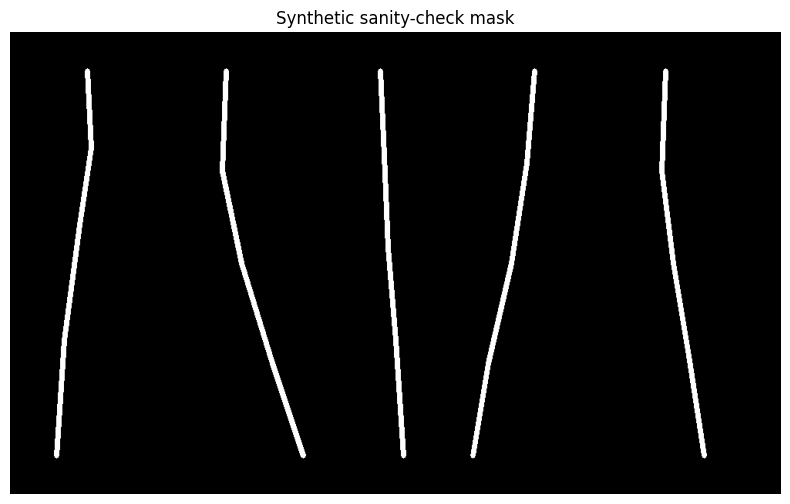

In [12]:
# Create a controlled binary image containing exactly 5 separate "roots"

synthetic_mask = np.zeros((600, 1000), dtype=np.uint8)

roots = [
    [(100, 50), (105, 150), (90, 250), (70, 400), (60, 550)],
    [(280, 50), (275, 180), (300, 300), (340, 430), (380, 550)],
    [(480, 50), (485, 160), (490, 280), (500, 400), (510, 550)],
    [(680, 50), (670, 170), (650, 300), (620, 430), (600, 550)],
    [(850, 50), (845, 180), (860, 300), (880, 420), (900, 550)]
]

for root in roots:
    pts = np.array(root, dtype=np.int32)
    cv2.polylines(
        synthetic_mask,
        [pts],
        isClosed=False,
        color=255,
        thickness=5
    )

plt.figure(figsize=(14, 6))
plt.imshow(synthetic_mask, cmap="gray")
plt.title("Synthetic sanity-check mask")
plt.axis("off")
plt.show()

In [13]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    synthetic_mask,
    connectivity=8
)

n_objects = num_labels - 1  # subtract background

print("Detected root systems:", n_objects)

assert n_objects == 5, \
    f"Sanity check failed: expected 5 roots, found {n_objects}"

print("PASS: connected-components detects exactly 5 roots.")

Detected root systems: 5
PASS: connected-components detects exactly 5 roots.


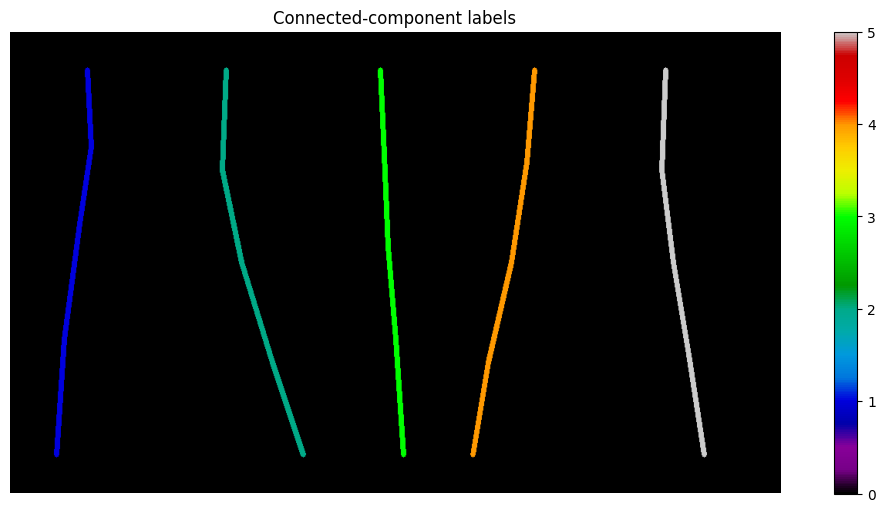

In [14]:
plt.figure(figsize=(14, 6))
plt.imshow(labels, cmap="nipy_spectral")
plt.title("Connected-component labels")
plt.colorbar()
plt.axis("off")
plt.show()

In [15]:
synthetic_instances = []

for label_id in range(1, num_labels):
    
    instance = np.zeros_like(synthetic_mask)
    instance[labels == label_id] = 255
    
    synthetic_instances.append(instance)

reconstructed = np.zeros_like(synthetic_mask)

for instance in synthetic_instances:
    reconstructed = cv2.bitwise_or(reconstructed, instance)

exact_match = np.array_equal(
    reconstructed,
    synthetic_mask
)

print("Exact pixel reconstruction:", exact_match)

assert exact_match, \
    "Reconstruction failed: pixels were lost or changed."

print("PASS: every root pixel was preserved.")

Exact pixel reconstruction: True
PASS: every root pixel was preserved.


In [16]:
instance_stack = np.stack(
    [(m > 0).astype(np.uint8) for m in synthetic_instances],
    axis=0
)

pixel_assignment_count = instance_stack.sum(axis=0)

overlap_pixels = np.sum(pixel_assignment_count > 1)

print("Pixels assigned to multiple roots:", overlap_pixels)

assert overlap_pixels == 0, \
    "Instance masks overlap."

print("PASS: no root pixel belongs to multiple instances.")

Pixels assigned to multiple roots: 0
PASS: no root pixel belongs to multiple instances.


In [17]:
MASK_PATH = "task5_test_image_prediction_nikasoleimanzadeh_244258.png"

root_mask = cv2.imread(
    MASK_PATH,
    cv2.IMREAD_GRAYSCALE
)

assert root_mask is not None, \
    f"Could not load {MASK_PATH}"

# Force strict binary representation
root_mask = (root_mask > 0).astype(np.uint8) * 255

print("Shape:", root_mask.shape)
print("Datatype:", root_mask.dtype)
print("Unique values:", np.unique(root_mask))
print("Root pixels:", np.sum(root_mask == 255))

Shape: (3006, 4112)
Datatype: uint8
Unique values: [  0 255]
Root pixels: 103428


In [18]:
assert root_mask.ndim == 2
assert set(np.unique(root_mask)).issubset({0, 255})

print("PASS: valid binary Task 5 root mask.")

PASS: valid binary Task 5 root mask.


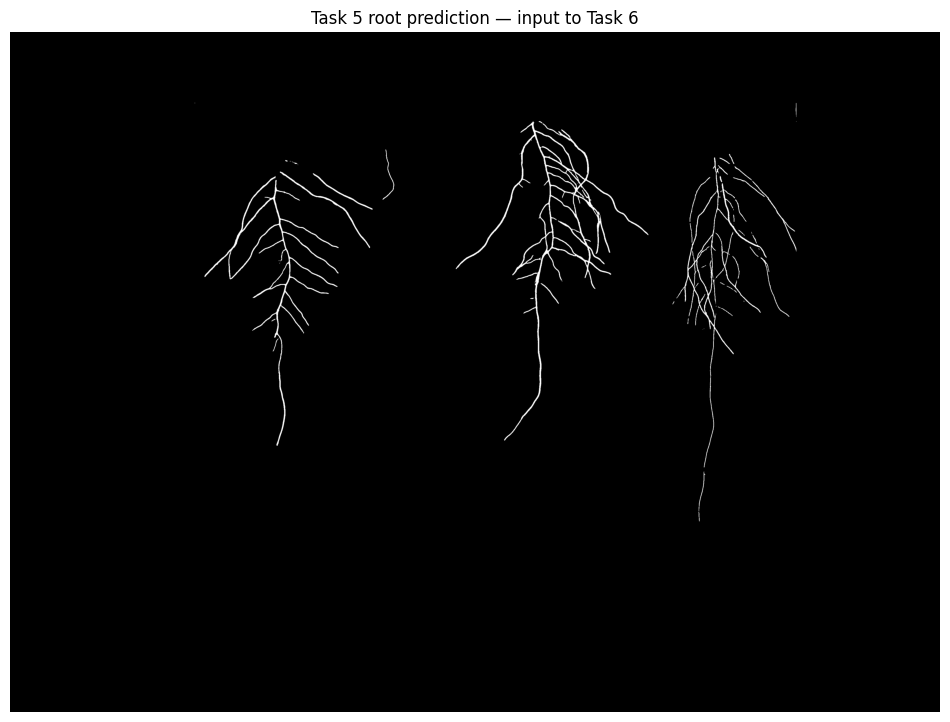

In [19]:
plt.figure(figsize=(12, 12))
plt.imshow(root_mask, cmap="gray")
plt.title("Task 5 root prediction — input to Task 6")
plt.axis("off")
plt.show()

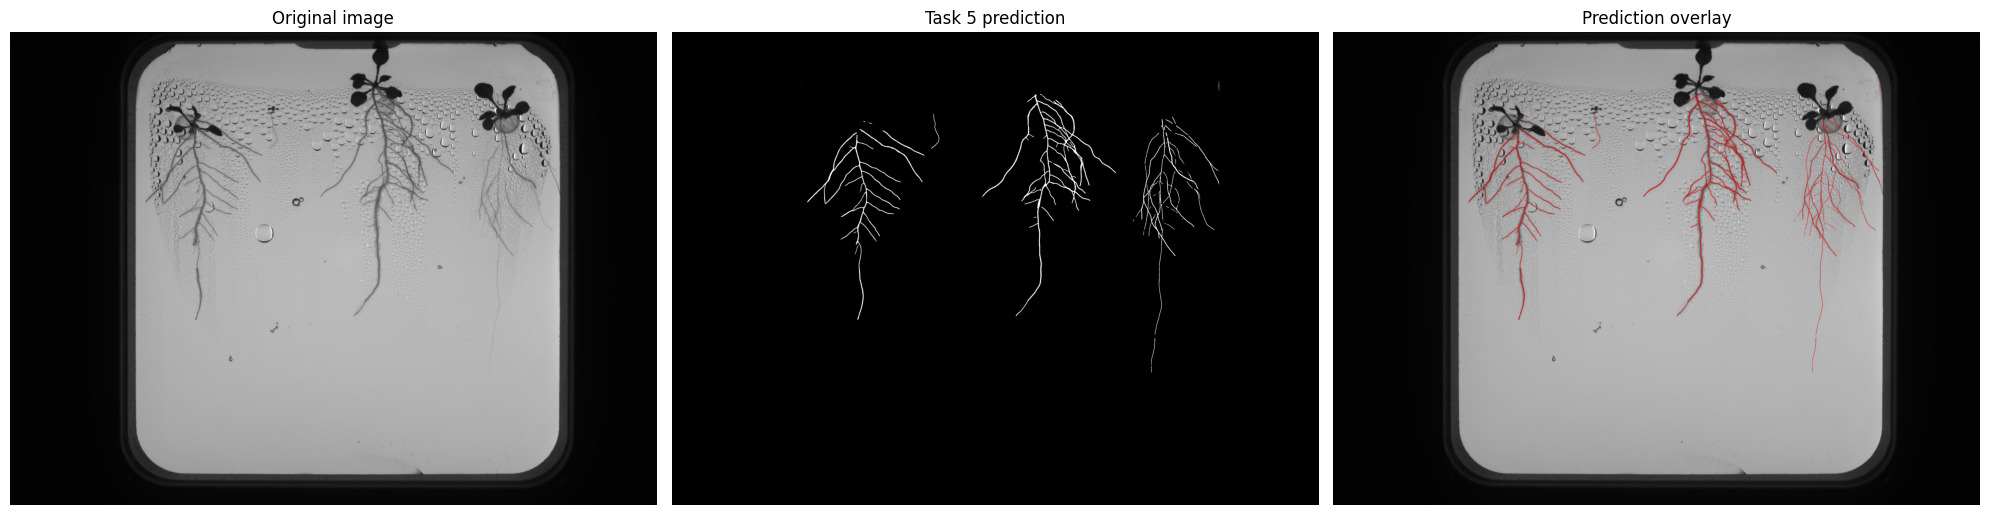

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Replace with the original image used for this U-Net segmentation prediction
IMAGE_PATH = "task5_test_image.png"

image = cv2.imread(IMAGE_PATH)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

assert image.shape[:2] == root_mask.shape, (
    f"Shape mismatch: image {image.shape[:2]}, mask {root_mask.shape}"
)

overlay = image.copy()

# Make predicted root pixels red
overlay[root_mask > 0] = (
    0.35 * overlay[root_mask > 0] +
    0.65 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].imshow(image)
axes[0].set_title("Original image")

axes[1].imshow(root_mask, cmap="gray")
axes[1].set_title("Task 5 prediction")

axes[2].imshow(overlay)
axes[2].set_title("Prediction overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# RAW CONNECTED COMPONENT ANALYSIS
# ============================================================

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    (root_mask > 0).astype(np.uint8),
    connectivity=8
)

n_components = num_labels - 1  # background is label 0

print(f"Foreground connected components found: {n_components}")

Foreground connected components found: 70


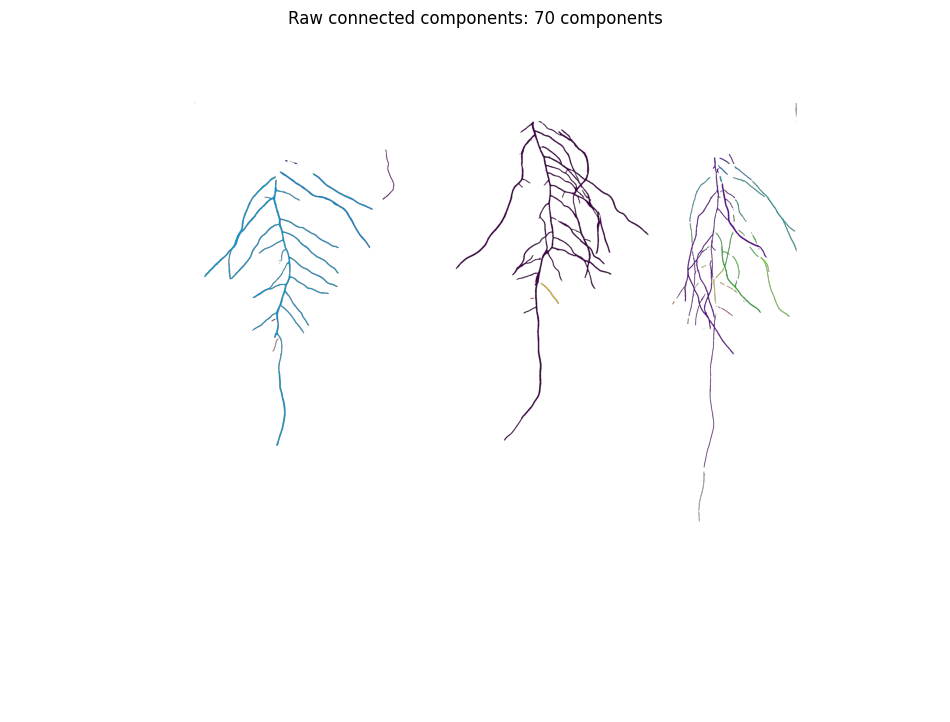

In [22]:
# Mask out the background so only root components are coloured
display_labels = np.ma.masked_where(labels == 0, labels)

plt.figure(figsize=(12, 10))
plt.imshow(display_labels, cmap="nipy_spectral")
plt.title(f"Raw connected components: {n_components} components")
plt.axis("off")
plt.show()

In [23]:
components = []

for label_id in range(1, num_labels):

    x, y, w, h, area = stats[label_id]
    cx, cy = centroids[label_id]

    components.append({
        "label": label_id,
        "area": int(area),
        "x": int(x),
        "y": int(y),
        "width": int(w),
        "height": int(h),
        "centroid_x": round(float(cx), 1),
        "centroid_y": round(float(cy), 1)
    })

# Largest first — ONLY for inspection, nothing is removed
components_sorted = sorted(
    components,
    key=lambda c: c["area"],
    reverse=True
)

for component in components_sorted:
    print(component)

{'label': 3, 'area': 43847, 'x': 1971, 'y': 394, 'width': 853, 'height': 1412, 'centroid_x': 2417.9, 'centroid_y': 856.2}
{'label': 22, 'area': 24729, 'x': 860, 'y': 637, 'width': 593, 'height': 1192, 'centroid_x': 1178.3, 'centroid_y': 1056.2}
{'label': 9, 'area': 16385, 'x': 2946, 'y': 554, 'width': 399, 'height': 1371, 'centroid_x': 3098.6, 'centroid_y': 1066.9}
{'label': 20, 'area': 3438, 'x': 1193, 'y': 617, 'width': 399, 'height': 338, 'centroid_x': 1406.8, 'centroid_y': 763.8}
{'label': 36, 'area': 2380, 'x': 3118, 'y': 883, 'width': 202, 'height': 358, 'centroid_x': 3194.5, 'centroid_y': 1056.2}
{'label': 21, 'area': 1872, 'x': 1339, 'y': 624, 'width': 265, 'height': 161, 'centroid_x': 1465.6, 'centroid_y': 710.8}
{'label': 26, 'area': 1733, 'x': 3281, 'y': 658, 'width': 196, 'height': 313, 'centroid_x': 3399.4, 'centroid_y': 813.5}
{'label': 44, 'area': 1148, 'x': 3319, 'y': 996, 'width': 127, 'height': 263, 'centroid_x': 3368.3, 'centroid_y': 1118.2}
{'label': 5, 'area': 871,

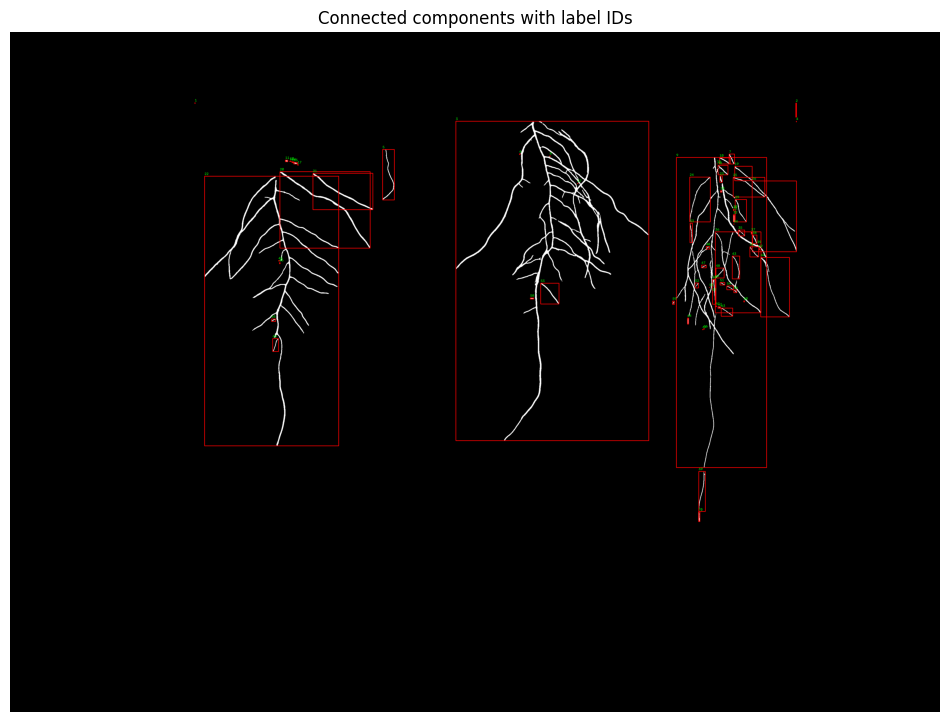

In [24]:
diagnostic = cv2.cvtColor(root_mask, cv2.COLOR_GRAY2RGB)

for component in components:

    x = component["x"]
    y = component["y"]
    w = component["width"]
    h = component["height"]
    label_id = component["label"]

    cv2.rectangle(
        diagnostic,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

    cv2.putText(
        diagnostic,
        str(label_id),
        (x, max(y - 5, 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        1,
        cv2.LINE_AA
    )

plt.figure(figsize=(12, 10))
plt.imshow(diagnostic)
plt.title("Connected components with label IDs")
plt.axis("off")
plt.show()

## Sec attempt

In [38]:
from scipy.signal import find_peaks
from scipy.spatial import cKDTree
import heapq

In [28]:
def detect_plant_centers_dynamic(image_rgb):
    """
    Detect plant/crown x-positions dynamically.

    No fixed number of plants is assumed.
    """

    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    h, w = gray.shape

    # Upper interior of the Petri dish where shoots/crowns occur
    x0 = int(0.20 * w)
    x1 = int(0.84 * w)

    y0 = int(0.06 * h)
    y1 = int(0.25 * h)

    roi = gray[y0:y1, x0:x1].astype(np.float32)

    # Dark plant material receives a high response
    reference = np.percentile(roi, 85)
    darkness = np.clip(reference - roi, 0, None)

    # Horizontal darkness projection
    projection = darkness.sum(axis=0)

    # Smooth noise while keeping separate plants distinct
    sigma = max(3, int(0.005 * w))

    projection_smooth = cv2.GaussianBlur(
        projection.reshape(1, -1),
        (0, 0),
        sigmaX=sigma
    ).ravel()

    # Dynamic peak requirement
    baseline = np.median(projection_smooth)
    peak_range = projection_smooth.max() - baseline

    prominence = max(
        0.06 * peak_range,
        1.0
    )

    # Prevent multiple peaks inside the same plant
    min_distance = max(
        20,
        int(0.065 * w)
    )

    peaks, properties = find_peaks(
        projection_smooth,
        prominence=prominence,
        distance=min_distance
    )

    centers = np.sort(peaks + x0)

    return {
        "centers": centers.astype(int),
        "projection": projection_smooth,
        "peaks": peaks,
        "x0": x0,
        "x1": x1,
        "y0": y0,
        "y1": y1
    }

In [29]:
plant_detection = detect_plant_centers_dynamic(image)

plant_centers = plant_detection["centers"]

print("Detected candidate plants:", len(plant_centers))
print("Plant x-positions:", plant_centers)

Detected candidate plants: 4
Plant x-positions: [1168 1667 2380 3037]


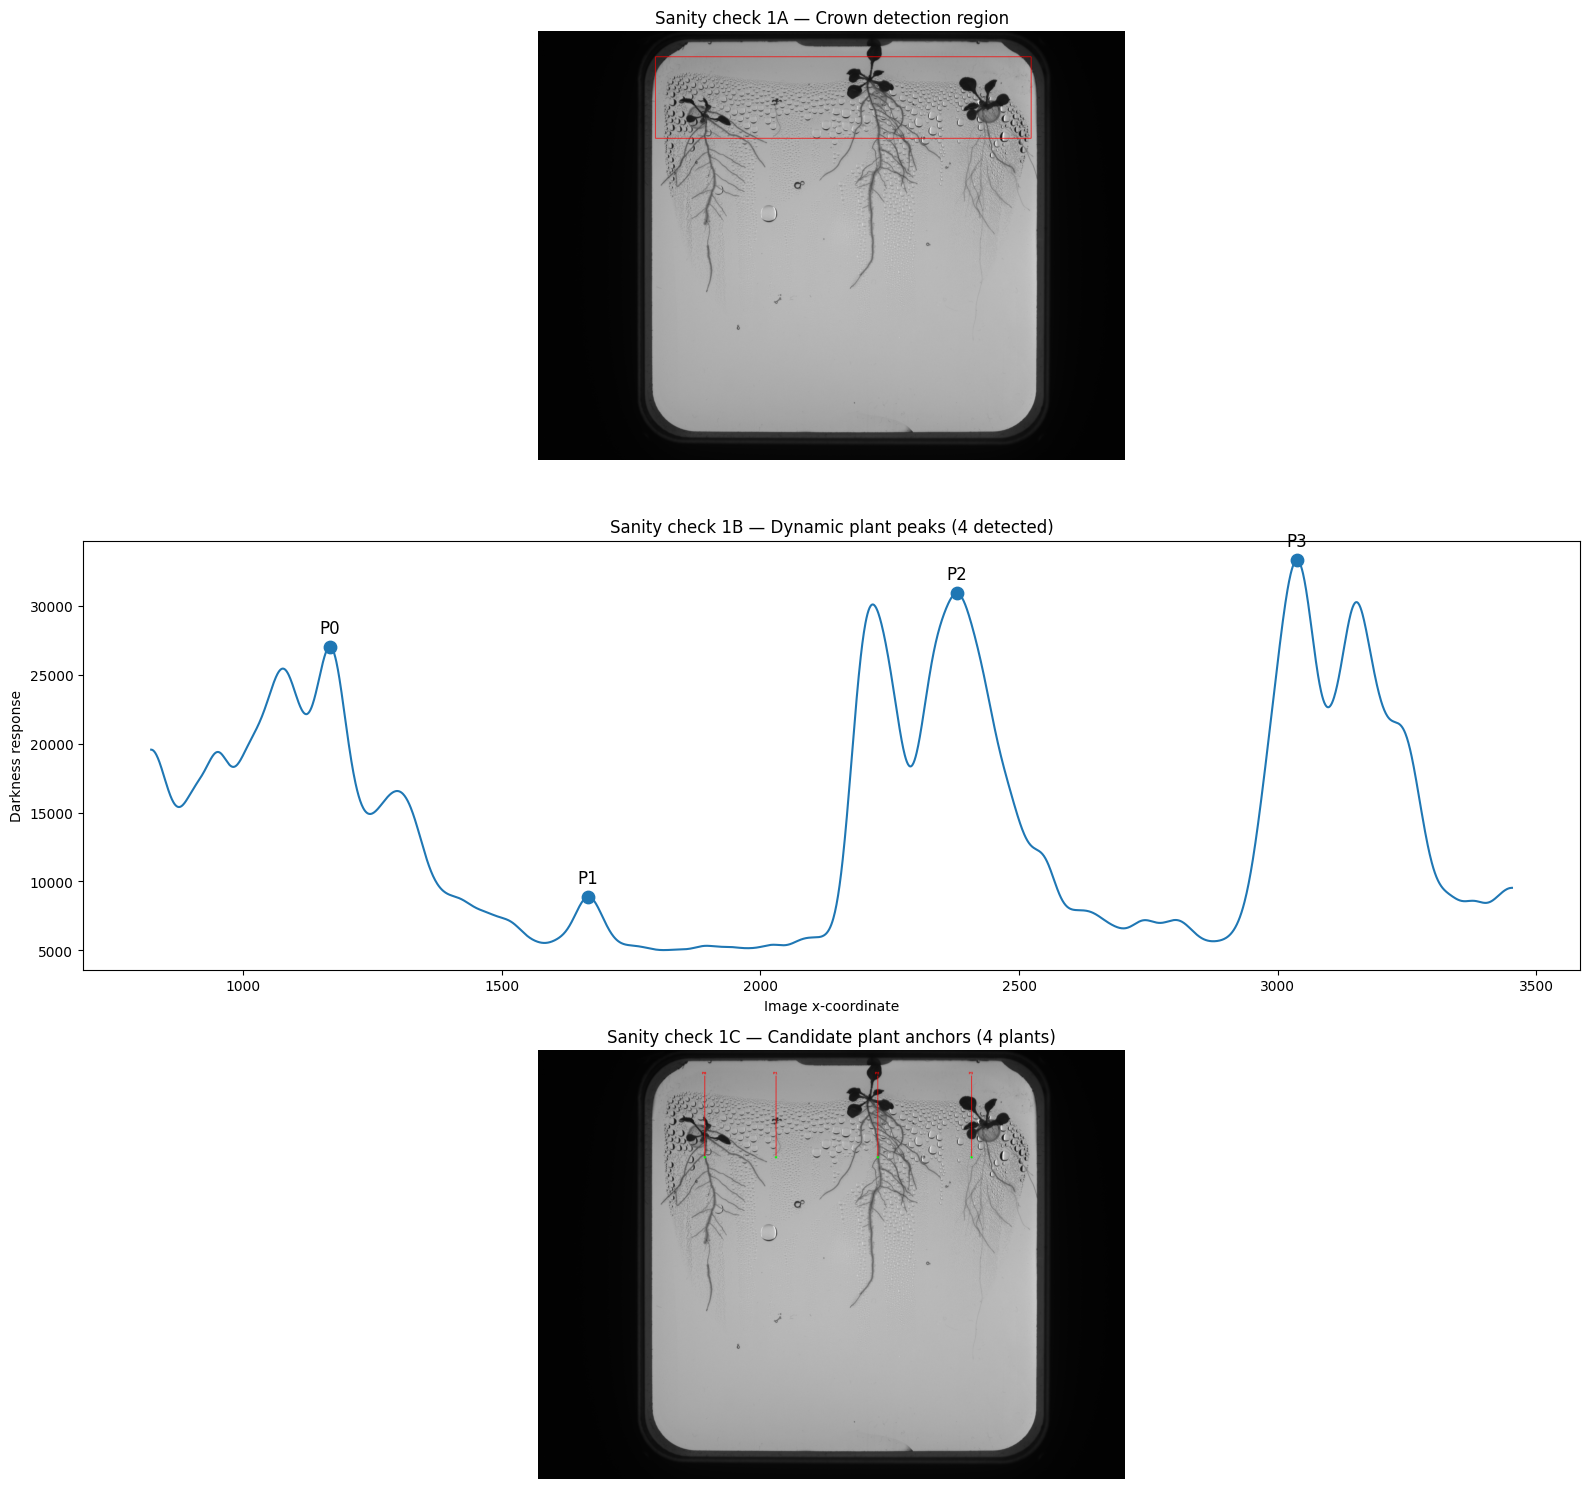

In [30]:
x0 = plant_detection["x0"]
x1 = plant_detection["x1"]
y0 = plant_detection["y0"]
y1 = plant_detection["y1"]

projection = plant_detection["projection"]
peaks = plant_detection["peaks"]

fig, axes = plt.subplots(3, 1, figsize=(16, 15))


# ------------------------------------------------------------
# 1. Show exactly which part of the image is being analysed
# ------------------------------------------------------------

roi_display = image.copy()

cv2.rectangle(
    roi_display,
    (x0, y0),
    (x1, y1),
    (255, 0, 0),
    3
)

axes[0].imshow(roi_display)
axes[0].set_title("Sanity check 1A — Crown detection region")
axes[0].axis("off")


# ------------------------------------------------------------
# 2. Show the darkness projection and detected peaks
# ------------------------------------------------------------

x_coordinates = np.arange(x0, x1)

axes[1].plot(
    x_coordinates,
    projection
)

axes[1].scatter(
    plant_centers,
    projection[peaks],
    s=80
)

for i, center_x in enumerate(plant_centers):

    axes[1].annotate(
        f"P{i}",
        (
            center_x,
            projection[peaks[i]]
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=12
    )

axes[1].set_title(
    f"Sanity check 1B — Dynamic plant peaks "
    f"({len(plant_centers)} detected)"
)

axes[1].set_xlabel("Image x-coordinate")
axes[1].set_ylabel("Darkness response")


# ------------------------------------------------------------
# 3. Draw detected plant positions on the ORIGINAL image
# ------------------------------------------------------------

anchor_display = image.copy()

for i, center_x in enumerate(plant_centers):

    cv2.line(
        anchor_display,
        (int(center_x), y0),
        (int(center_x), y1),
        (255, 0, 0),
        3
    )

    cv2.circle(
        anchor_display,
        (int(center_x), y1),
        8,
        (0, 255, 0),
        -1
    )

    cv2.putText(
        anchor_display,
        f"P{i}",
        (int(center_x) - 20, y0 - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 0, 0),
        2,
        cv2.LINE_AA
    )

axes[2].imshow(anchor_display)

axes[2].set_title(
    f"Sanity check 1C — Candidate plant anchors "
    f"({len(plant_centers)} plants)"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# individual root segmentation — STEP 2C
# Choose root-origin seed using main-root evidence
# ============================================================

binary_root = (root_mask > 0).astype(np.uint8)

h, w = binary_root.shape

num_labels, fragment_labels, stats, centroids = \
    cv2.connectedComponentsWithStats(
        binary_root,
        connectivity=8
    )

plant_seeds = []

for plant_id, center_x in enumerate(plant_centers):

    # Search locally around the plant crown
    half_width = int(0.055 * w)

    sx0 = max(0, int(center_x - half_width))
    sx1 = min(w, int(center_x + half_width))

    sy0 = y0
    sy1 = min(h, int(y1 + 0.18 * h))

    candidate_labels = np.unique(
        fragment_labels[sy0:sy1, sx0:sx1]
    )

    candidate_labels = candidate_labels[
        candidate_labels != 0
    ]

    best_label = None
    best_score = -np.inf

    for label_id in candidate_labels:

        ys, xs = np.where(
            fragment_labels == label_id
        )

        # Restrict evaluation to fragments actually near this plant
        near = (
            (xs >= sx0) &
            (xs < sx1) &
            (ys >= sy0) &
            (ys < sy1)
        )

        if not np.any(near):
            continue

        xs_near = xs[near]
        ys_near = ys[near]

        top_y = ys_near.min()
        bottom_y = ys_near.max()

        vertical_span = bottom_y - top_y

        median_x = np.median(xs_near)

        horizontal_distance = abs(
            median_x - center_x
        )

        pixel_count = len(xs_near)

        # Prefer:
        # 1. fragments extending downward
        # 2. fragments close to plant centre
        # 3. fragments with meaningful support
        score = (
            3.0 * vertical_span
            - 1.5 * horizontal_distance
            + 0.02 * pixel_count
        )

        if score > best_score:
            best_score = score
            best_label = int(label_id)

    if best_label is None:
        plant_seeds.append(None)

        print(
            f"WARNING: Plant {plant_id}: "
            "no suitable root fragment found."
        )

        continue

    # --------------------------------------------------------
    # Choose the root origin from the selected main fragment
    # --------------------------------------------------------

    ys, xs = np.where(
        fragment_labels == best_label
    )

    # Only use pixels reasonably close to this plant
    near = (
        (xs >= sx0) &
        (xs < sx1) &
        (ys >= sy0) &
        (ys < sy1)
    )

    xs = xs[near]
    ys = ys[near]

    top_y = ys.min()

    # Small top band prevents one noisy pixel controlling the seed
    top_band = ys <= top_y + 12

    xs_top = xs[top_band]
    ys_top = ys[top_band]

    best_pixel = np.argmin(
        np.abs(xs_top - center_x)
    )

    seed_x = int(xs_top[best_pixel])
    seed_y = int(ys_top[best_pixel])

    plant_seeds.append({
        "plant_id": plant_id,
        "x": seed_x,
        "y": seed_y,
        "fragment_id": best_label,
        "score": float(best_score)
    })

    print(
        f"Plant {plant_id}: "
        f"seed=({seed_x}, {seed_y}), "
        f"fragment={best_label}, "
        f"score={best_score:.1f}"
    )

Plant 0: seed=(1168, 641), fragment=22, score=2324.5
Plant 1: seed=(1664, 527), fragment=5, score=674.4
Plant 2: seed=(2360, 406), fragment=3, score=3338.8
Plant 3: seed=(3113, 556), fragment=9, score=2392.9


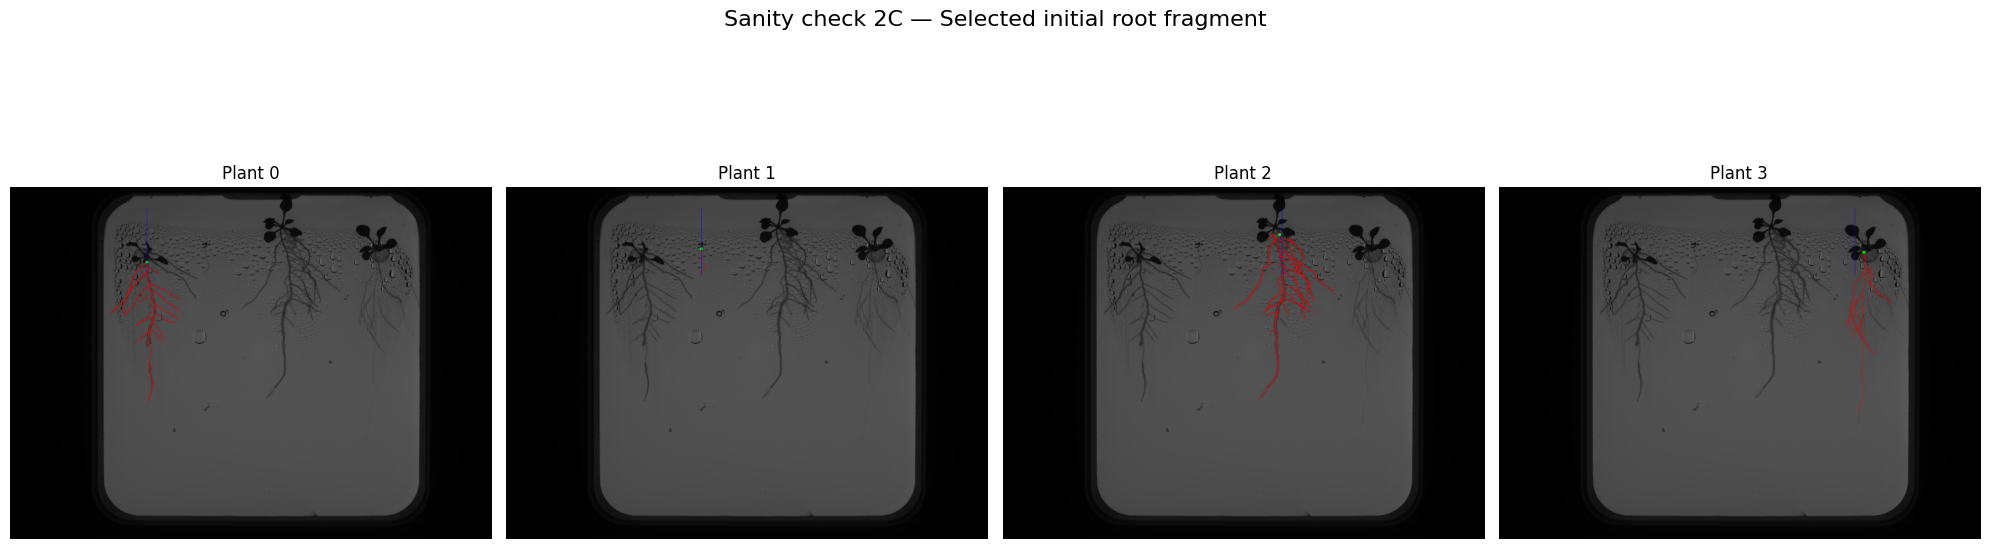

In [37]:
# ============================================================
# SANITY CHECK 2C
# Selected starting fragment for every plant
# ============================================================

fig, axes = plt.subplots(
    1,
    len(plant_centers),
    figsize=(5 * len(plant_centers), 7)
)

if len(plant_centers) == 1:
    axes = [axes]

for plant_id, ax in enumerate(axes):

    seed = plant_seeds[plant_id]

    display = image.copy()

    # Fade whole image
    display = (
        display.astype(np.float32) * 0.45
    ).astype(np.uint8)

    if seed is not None:

        label_id = seed["fragment_id"]

        selected_fragment = (
            fragment_labels == label_id
        )

        # Selected U-Net segmentation fragment in red
        display[selected_fragment] = [255, 0, 0]

        # Seed in green
        cv2.circle(
            display,
            (seed["x"], seed["y"]),
            12,
            (0, 255, 0),
            -1
        )

        # Detected plant centre
        cv2.line(
            display,
            (int(plant_centers[plant_id]), y0),
            (int(plant_centers[plant_id]), y1),
            (0, 0, 255),
            2
        )

    ax.imshow(display)
    ax.set_title(f"Plant {plant_id}")
    ax.axis("off")

plt.suptitle(
    "Sanity check 2C — Selected initial root fragment",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [33]:
valid_seeds = [
    s for s in plant_seeds
    if s is not None
]

seed_fragments = [
    s["fragment_id"]
    for s in valid_seeds
]

print(
    "Plants detected:",
    len(plant_centers)
)

print(
    "Plants with root seeds:",
    len(valid_seeds)
)

print(
    "Unique initial root fragments:",
    len(set(seed_fragments))
)

if len(seed_fragments) != len(set(seed_fragments)):
    print(
        "WARNING: Two or more plants currently point "
        "to the same root fragment."
    )
else:
    print(
        "PASS: every plant begins from a different root fragment."
    )

Plants detected: 4
Plants with root seeds: 4
Unique initial root fragments: 4
PASS: every plant begins from a different root fragment.


In [39]:
# ============================================================
# individual root segmentation — STEP 3
# Build distances between disconnected root fragments
# ============================================================

component_ids = list(range(1, num_labels))

component_pixels = {}
component_trees = {}

for label_id in component_ids:

    ys, xs = np.where(fragment_labels == label_id)

    coords = np.column_stack((ys, xs))

    component_pixels[label_id] = coords
    component_trees[label_id] = cKDTree(coords)


def bbox_distance(label_a, label_b):
    """Fast minimum possible distance between two bounding boxes."""

    xa, ya, wa, ha, _ = stats[label_a]
    xb, yb, wb, hb, _ = stats[label_b]

    ax2 = xa + wa - 1
    ay2 = ya + ha - 1

    bx2 = xb + wb - 1
    by2 = yb + hb - 1

    dx = max(
        xb - ax2,
        xa - bx2,
        0
    )

    dy = max(
        yb - ay2,
        ya - by2,
        0
    )

    return np.hypot(dx, dy)


# Largest gap we are even willing to investigate.
# This DOES NOT mean all gaps this size will be accepted.
MAX_TEST_GAP = int(0.025 * min(h, w))

fragment_edges = {
    label_id: []
    for label_id in component_ids
}

for i, label_a in enumerate(component_ids):

    for label_b in component_ids[i + 1:]:

        # Skip obviously distant components
        if bbox_distance(label_a, label_b) > MAX_TEST_GAP:
            continue

        coords_a = component_pixels[label_a]
        coords_b = component_pixels[label_b]

        # Query using the smaller component
        if len(coords_a) <= len(coords_b):

            distances, _ = component_trees[label_b].query(
                coords_a,
                k=1
            )

        else:

            distances, _ = component_trees[label_a].query(
                coords_b,
                k=1
            )

        gap = float(np.min(distances))

        if gap <= MAX_TEST_GAP:

            fragment_edges[label_a].append(
                (label_b, gap)
            )

            fragment_edges[label_b].append(
                (label_a, gap)
            )

print("Fragment graph created.")
print("Maximum inspected gap:", MAX_TEST_GAP, "pixels")

Fragment graph created.
Maximum inspected gap: 75 pixels


In [41]:
# ============================================================
# Multi-source fragment assignment
# ============================================================

def assign_fragments(max_gap_px):

    best_cost = {
        label_id: np.inf
        for label_id in component_ids
    }

    owner = {
        label_id: None
        for label_id in component_ids
    }

    queue = []

    # Each plant's initial root fragment is a graph seed
    for seed in plant_seeds:

        if seed is None:
            continue

        label_id = seed["fragment_id"]
        plant_id = seed["plant_id"]

        best_cost[label_id] = 0.0
        owner[label_id] = plant_id

        heapq.heappush(
            queue,
            (0.0, plant_id, label_id)
        )

    while queue:

        cost, plant_id, current = heapq.heappop(queue)

        if cost > best_cost[current]:
            continue

        for neighbour, gap in fragment_edges[current]:

            if gap > max_gap_px:
                continue

            # Bottleneck cost:
            # largest gap needed along this route
            new_cost = max(cost, gap)

            if new_cost < best_cost[neighbour]:

                best_cost[neighbour] = new_cost
                owner[neighbour] = plant_id

                heapq.heappush(
                    queue,
                    (
                        new_cost,
                        plant_id,
                        neighbour
                    )
                )

    return owner, best_cost

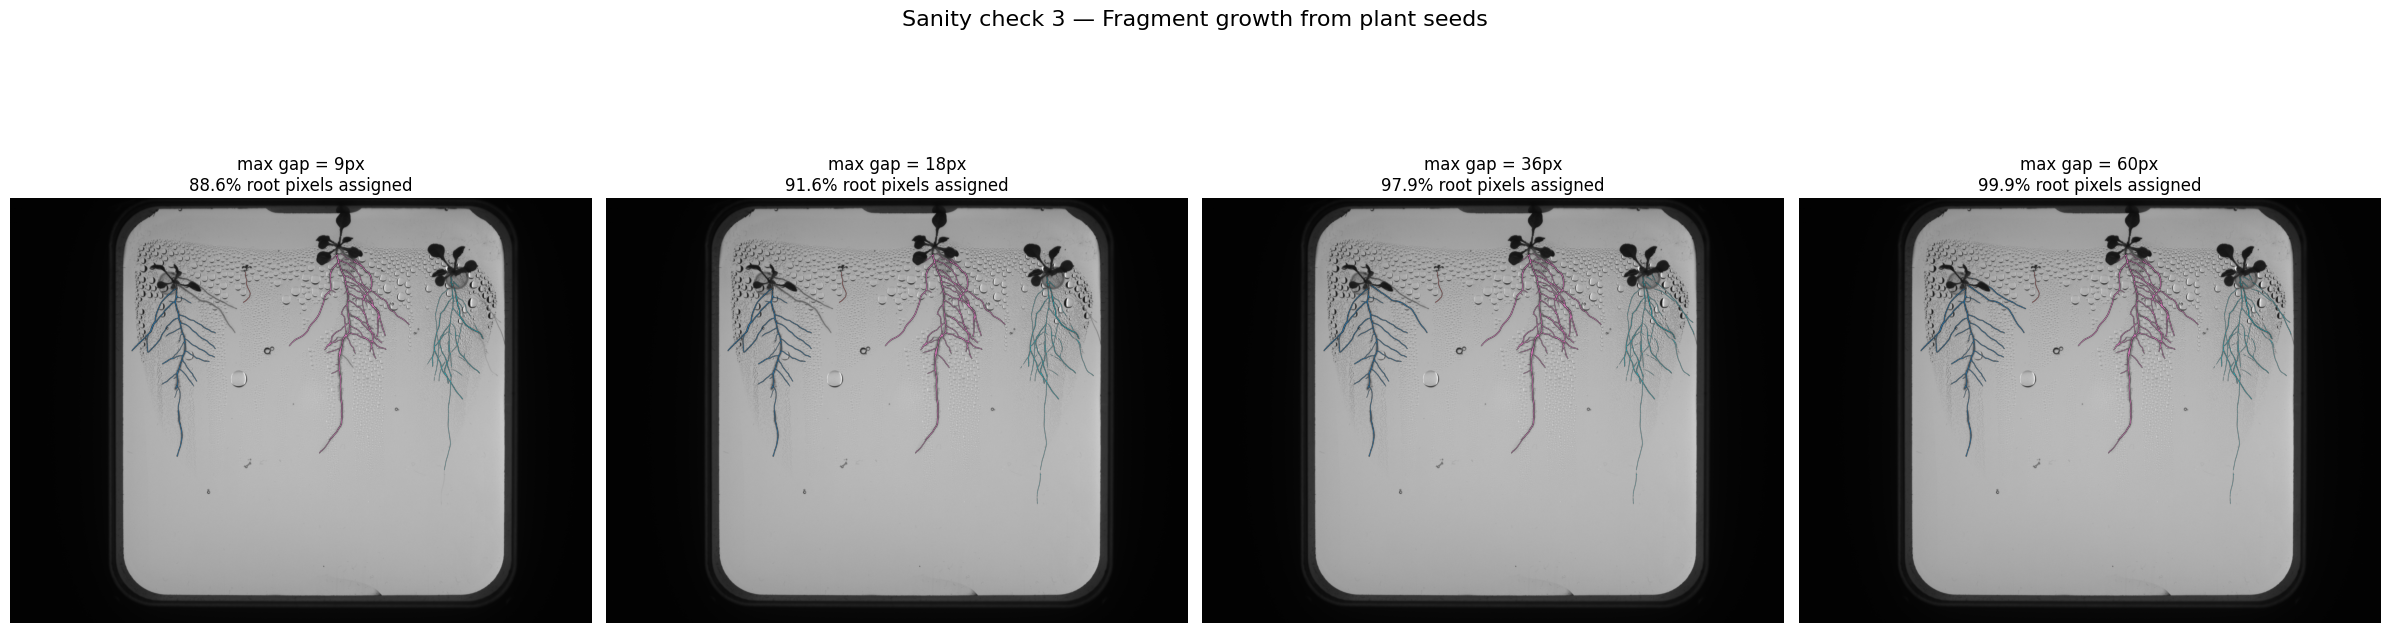

In [42]:
# ============================================================
# SANITY CHECK 3
# Test several fragment-connection distances
# ============================================================

test_ratios = [
    0.003,
    0.006,
    0.012,
    0.020
]

fig, axes = plt.subplots(
    1,
    len(test_ratios),
    figsize=(24, 8)
)

for ax, ratio in zip(axes, test_ratios):

    gap_px = max(
        2,
        int(ratio * min(h, w))
    )

    owner, costs = assign_fragments(gap_px)

    instance_map = np.zeros_like(
        fragment_labels,
        dtype=np.int32
    )

    for label_id, plant_id in owner.items():

        if plant_id is None:
            continue

        instance_map[
            fragment_labels == label_id
        ] = plant_id + 1

    total_root_pixels = np.sum(binary_root > 0)

    assigned_pixels = np.sum(instance_map > 0)

    assigned_percent = (
        100 * assigned_pixels /
        max(total_root_pixels, 1)
    )

    # Original image underneath
    ax.imshow(image)

    # Show assigned root systems
    masked_instances = np.ma.masked_where(
        instance_map == 0,
        instance_map
    )

    ax.imshow(
        masked_instances,
        cmap="tab10",
        alpha=0.85,
        vmin=1,
        vmax=max(len(plant_centers), 1)
    )

    ax.set_title(
        f"max gap = {gap_px}px\n"
        f"{assigned_percent:.1f}% root pixels assigned"
    )

    ax.axis("off")

plt.suptitle(
    "Sanity check 3 — Fragment growth from plant seeds",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# SANITY CHECK 4
# Inspect what remains UNASSIGNED at the candidate threshold
# ============================================================

FINAL_GAP_RATIO = 0.012
final_gap_px = max(2, int(FINAL_GAP_RATIO * min(h, w)))

final_owner, final_costs = assign_fragments(final_gap_px)

final_instance_map = np.zeros_like(fragment_labels, dtype=np.int32)

for label_id, plant_id in final_owner.items():

    if plant_id is None:
        continue

    final_instance_map[
        fragment_labels == label_id
    ] = plant_id + 1


assigned_mask = final_instance_map > 0

unassigned_mask = (
    (binary_root > 0) &
    (~assigned_mask)
)


print("Chosen gap:", final_gap_px, "px")
print("Total root pixels:", np.sum(binary_root > 0))
print("Assigned root pixels:", np.sum(assigned_mask))
print("Unassigned root pixels:", np.sum(unassigned_mask))

print(
    "Assigned percentage:",
    round(
        100 * np.sum(assigned_mask) /
        np.sum(binary_root > 0),
        2
    ),
    "%"
)

Chosen gap: 36 px
Total root pixels: 103428
Assigned root pixels: 101291
Unassigned root pixels: 2137
Assigned percentage: 97.93 %


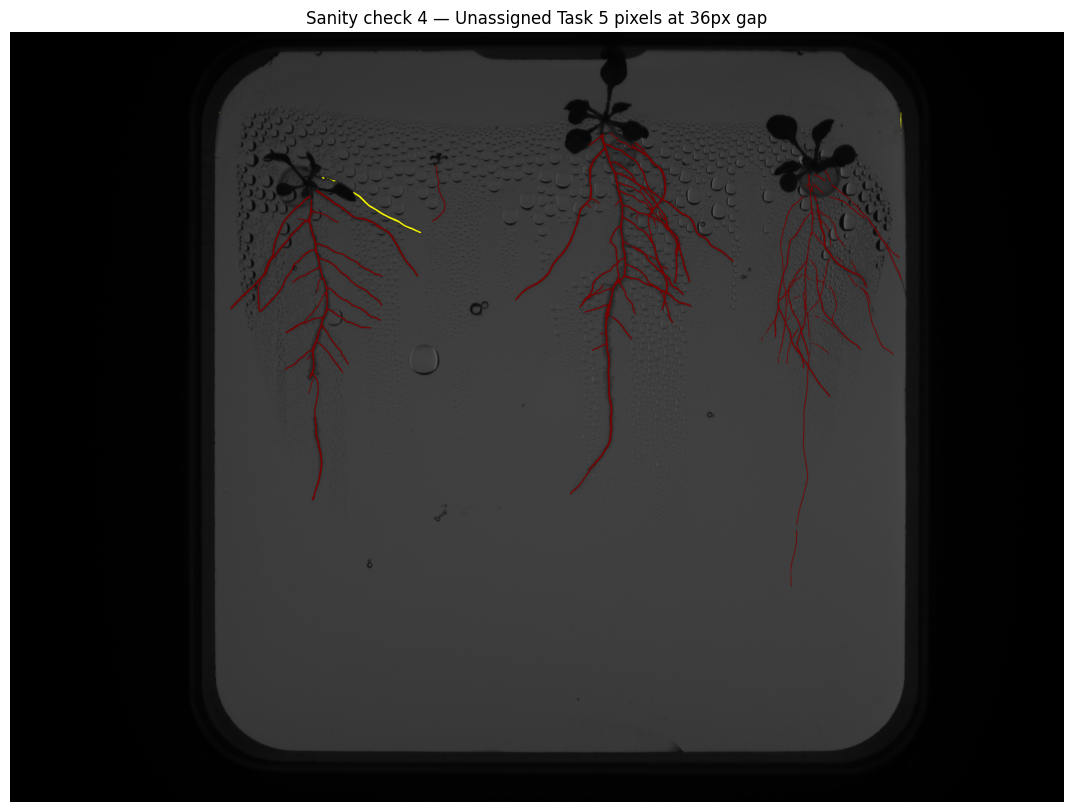

In [44]:
unassigned_display = image.copy()

# Fade image
unassigned_display = (
    unassigned_display.astype(np.float32) * 0.35
).astype(np.uint8)

# All U-Net segmentation root pixels = dark red
unassigned_display[binary_root > 0] = [120, 0, 0]

# Unassigned pixels = bright yellow
unassigned_display[unassigned_mask] = [255, 255, 0]


plt.figure(figsize=(14, 10))

plt.imshow(unassigned_display)

plt.title(
    f"Sanity check 4 — Unassigned Task 5 pixels "
    f"at {final_gap_px}px gap"
)

plt.axis("off")
plt.show()

In [46]:
# ============================================================
# SANITY CHECK 5
# What extra root pixels do we gain when going 36 -> 60 px?
# ============================================================

gap_36 = 36
gap_60 = 60

owner_36, _ = assign_fragments(gap_36)
owner_60, _ = assign_fragments(gap_60)

map_36 = np.zeros_like(fragment_labels, dtype=np.int32)
map_60 = np.zeros_like(fragment_labels, dtype=np.int32)

for label_id, plant_id in owner_36.items():
    if plant_id is not None:
        map_36[fragment_labels == label_id] = plant_id + 1

for label_id, plant_id in owner_60.items():
    if plant_id is not None:
        map_60[fragment_labels == label_id] = plant_id + 1

assigned_36 = map_36 > 0
assigned_60 = map_60 > 0

newly_added = assigned_60 & (~assigned_36)

print("Assigned at 36 px:", np.sum(assigned_36))
print("Assigned at 60 px:", np.sum(assigned_60))
print("Newly added pixels:", np.sum(newly_added))

Assigned at 36 px: 101291
Assigned at 60 px: 103292
Newly added pixels: 2001


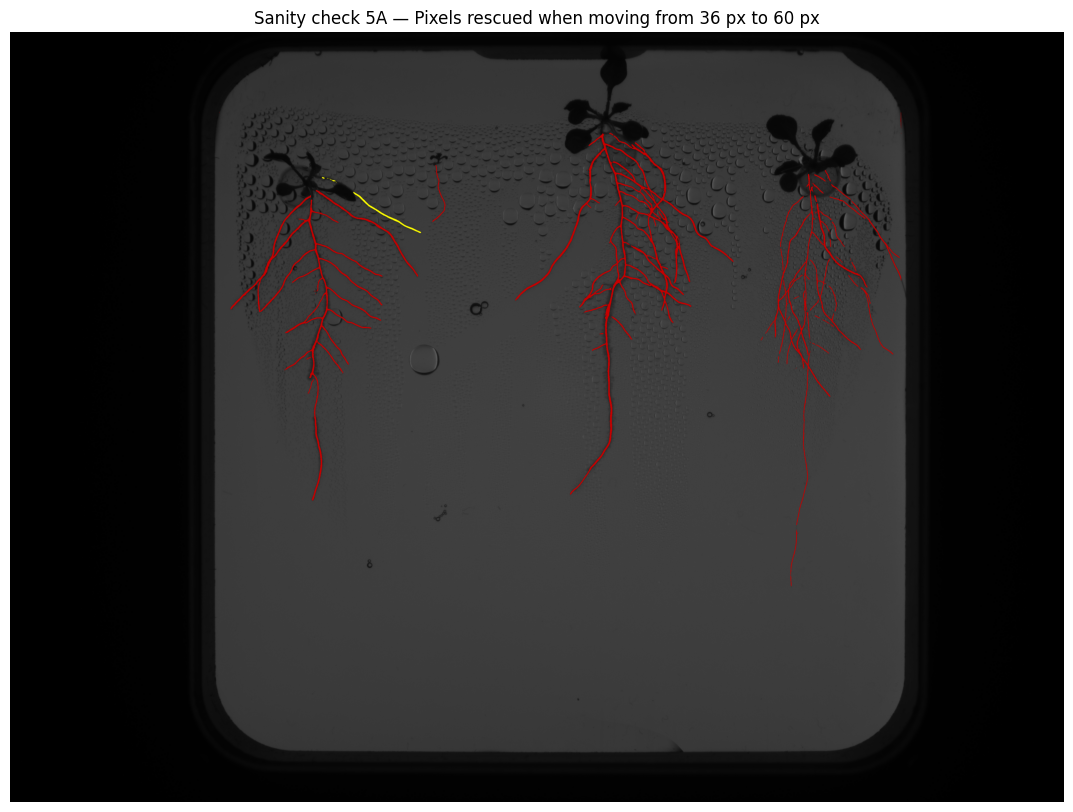

In [47]:
compare_display = image.copy()
compare_display = (compare_display.astype(np.float32) * 0.35).astype(np.uint8)

# all U-Net segmentation root pixels in dark red
compare_display[binary_root > 0] = [120, 0, 0]

# already assigned at 36 px in red
compare_display[assigned_36] = [200, 0, 0]

# newly rescued by 60 px in bright yellow
compare_display[newly_added] = [255, 255, 0]

plt.figure(figsize=(14, 10))
plt.imshow(compare_display)
plt.title("Sanity check 5A — Pixels rescued when moving from 36 px to 60 px")
plt.axis("off")
plt.show()

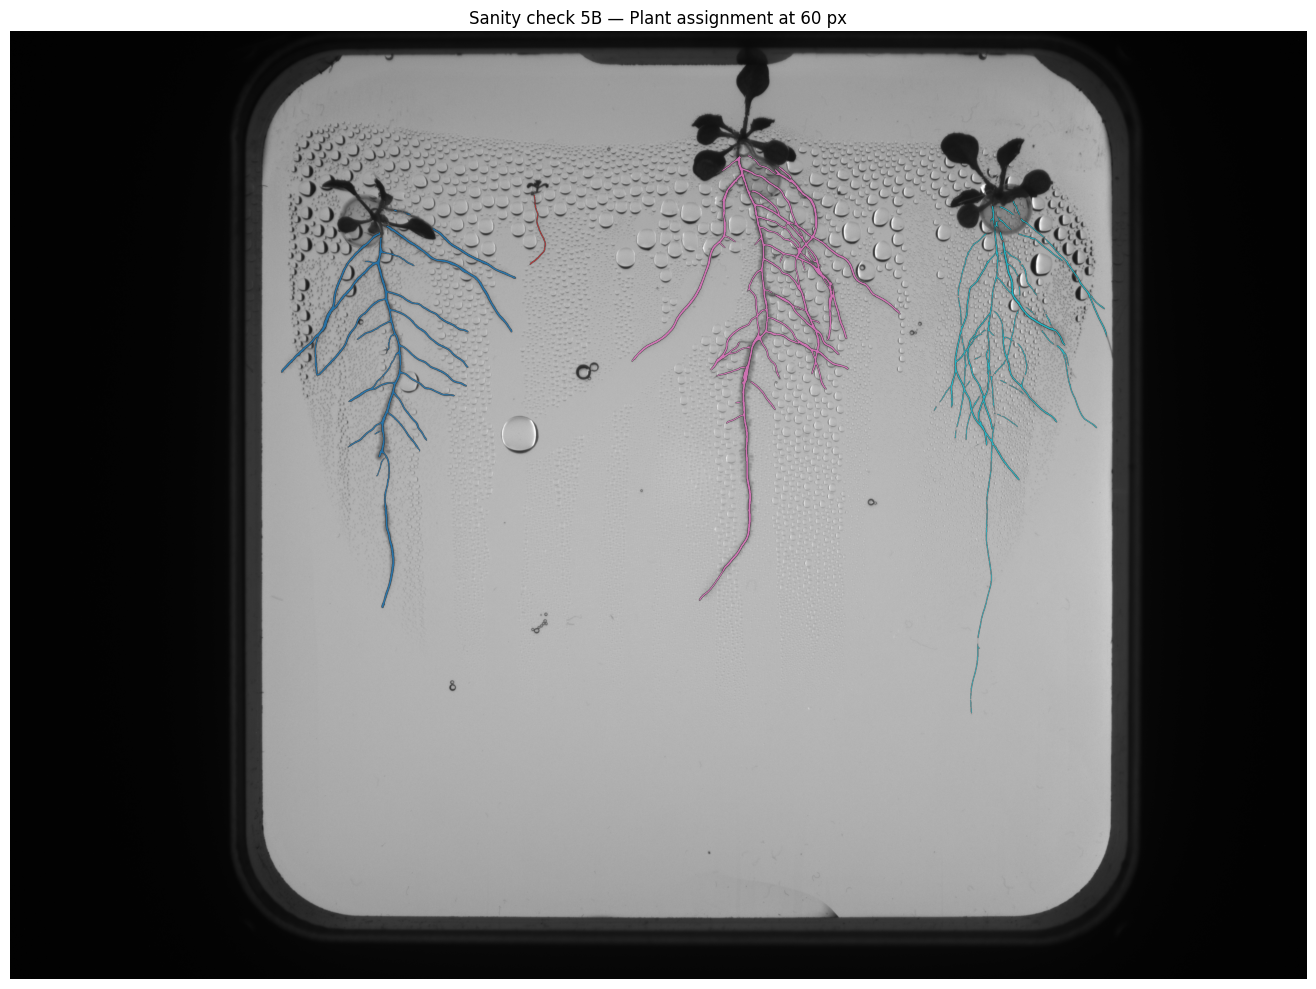

In [48]:
fig, ax = plt.subplots(figsize=(14, 10))

ax.imshow(image)

masked_map_60 = np.ma.masked_where(map_60 == 0, map_60)
ax.imshow(masked_map_60, cmap="tab10", alpha=0.85, vmin=1, vmax=max(len(plant_centers), 1))

ax.set_title("Sanity check 5B — Plant assignment at 60 px")
ax.axis("off")

plt.tight_layout()
plt.show()

In [50]:
# ============================================================
# individual root segmentation — FINAL INSTANCE SEGMENTATION
# ============================================================

FINAL_GAP_RATIO = 0.020

final_gap_px = max(
    2,
    int(FINAL_GAP_RATIO * min(h, w))
)

final_owner, final_costs = assign_fragments(final_gap_px)

final_instance_map = np.zeros_like(
    fragment_labels,
    dtype=np.int32
)

for label_id, plant_id in final_owner.items():

    if plant_id is None:
        continue

    final_instance_map[
        fragment_labels == label_id
    ] = plant_id + 1


individual_root_masks = []

for plant_id in range(len(plant_centers)):

    plant_mask = (
        final_instance_map == (plant_id + 1)
    ).astype(np.uint8)

    individual_root_masks.append(plant_mask)

print(
    f"Created {len(individual_root_masks)} "
    "individual root masks."
)

Created 4 individual root masks.


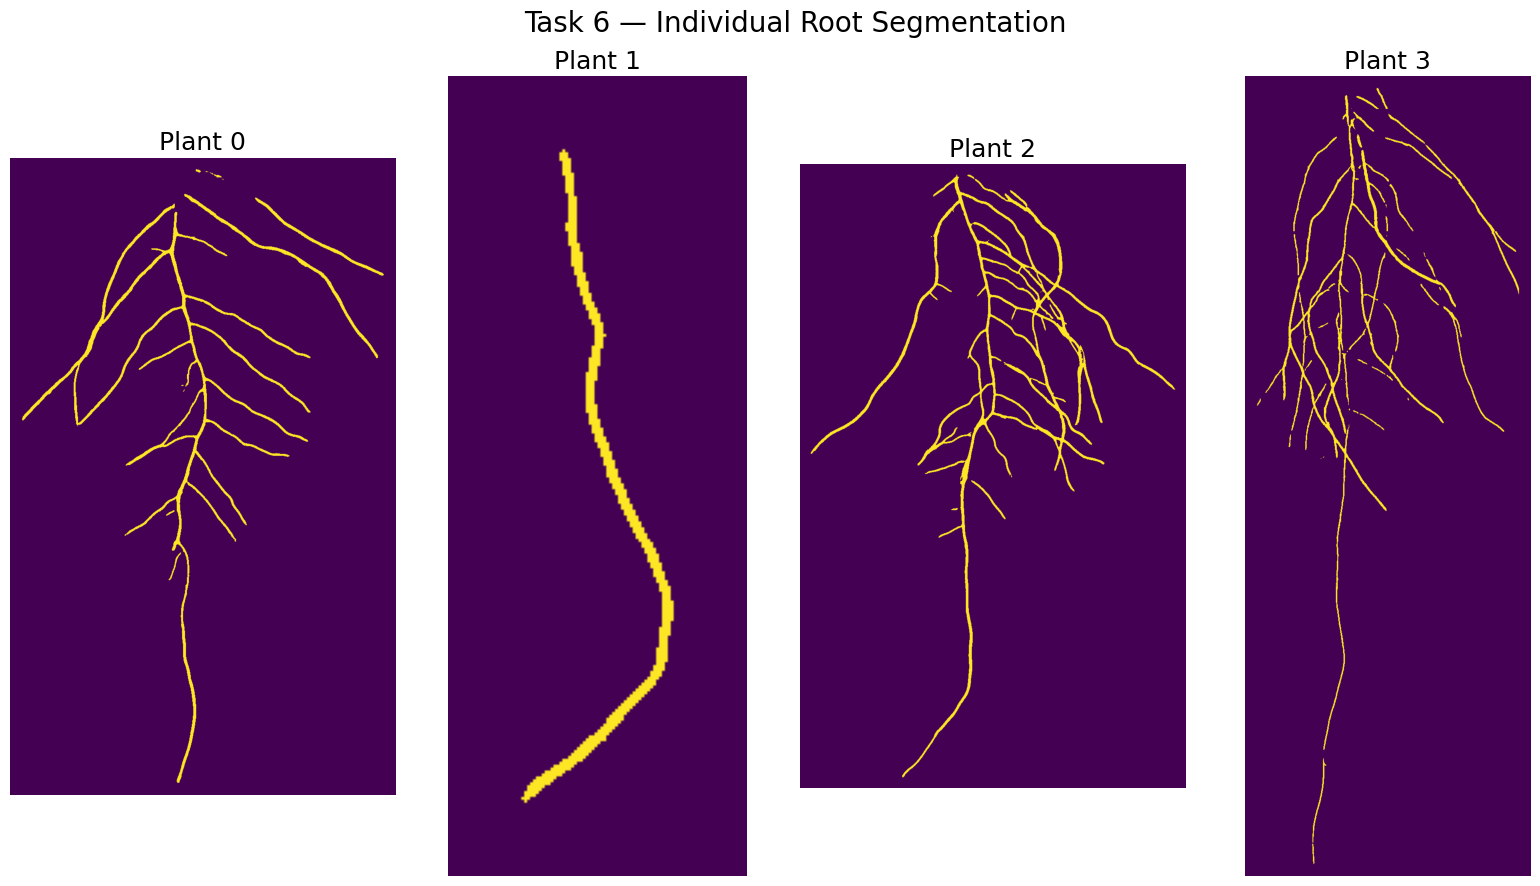

In [51]:
fig, axes = plt.subplots(
    1,
    len(individual_root_masks),
    figsize=(4 * len(individual_root_masks), 9)
)

if len(individual_root_masks) == 1:
    axes = [axes]

for plant_id, (mask, ax) in enumerate(
    zip(individual_root_masks, axes)
):

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:

        ax.imshow(mask, cmap="viridis")
        ax.set_title(f"Plant {plant_id}\nNo root detected")
        ax.axis("off")
        continue

    padding = 25

    xmin = max(0, xs.min() - padding)
    xmax = min(w, xs.max() + padding + 1)

    ymin = max(0, ys.min() - padding)
    ymax = min(h, ys.max() + padding + 1)

    crop = mask[
        ymin:ymax,
        xmin:xmax
    ]

    ax.imshow(
        crop,
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Plant {plant_id}",
        fontsize=18
    )

    ax.axis("off")

plt.suptitle(
    "Task 6 — Individual Root Segmentation",
    fontsize=20
)

plt.tight_layout()
plt.show()

In [52]:
# ============================================================
# FINAL individual root segmentation SANITY CHECKS
# ============================================================

stack = np.stack(
    individual_root_masks,
    axis=0
)

assignment_count = stack.sum(axis=0)

overlap_pixels = np.sum(
    assignment_count > 1
)

assigned_pixels = np.sum(
    assignment_count > 0
)

total_root_pixels = np.sum(
    binary_root > 0
)

coverage = (
    100 * assigned_pixels /
    max(total_root_pixels, 1)
)

unassigned_pixels = (
    total_root_pixels - assigned_pixels
)

print("Plants detected:", len(plant_centers))
print("Root masks created:", len(individual_root_masks))
print("Overlapping pixels:", overlap_pixels)
print("Unassigned root pixels:", unassigned_pixels)
print(f"Task 5 root pixels retained: {coverage:.2f}%")

assert len(individual_root_masks) == len(plant_centers)
assert overlap_pixels == 0

print("PASS: every instance has a unique plant identity.")

Plants detected: 4
Root masks created: 4
Overlapping pixels: 0
Unassigned root pixels: 136
Task 5 root pixels retained: 99.87%
PASS: every instance has a unique plant identity.


In [53]:
# root architecture extraction input
task6_root_masks = individual_root_masks

print(f"Task 6 complete: {len(task6_root_masks)} individual root systems ready.")

Task 6 complete: 4 individual root systems ready.


# root architecture extraction — Root System Architecture (RSA) Extraction

The individual root masks obtained in individual root assignment are converted into one-pixel-wide
skeletons. The skeletons preserve the topology of each root system while
allowing branches, endpoints, junctions and path lengths to be analysed.

Skan is used to extract branch-level information and NetworkX is used to analyse
paths through multiple connected branches. The final goal is to identify the
primary root and measure its length.

In [13]:
# ============================================================
# root architecture extraction — IMPORTS
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.spatial import cKDTree
from skimage.morphology import skeletonize
from skan import Skeleton, summarize

In [14]:
from pathlib import Path
import sys
import torch
import cv2
import numpy as np

ROOTNAV_DIR = Path("/home/y2a/RootNav-2.0/inference")

sys.path.insert(0, str(ROOTNAV_DIR.resolve()))

from models import ModelLoader

In [15]:
use_cuda = torch.cuda.is_available()

rootnav_data = ModelLoader.get_model(
    "arabidopsis_plate",
    gpu=use_cuda
)

rootnav_model = rootnav_data["model"]

print("RootNav loaded.")

Loading model...Done
RootNav loaded.


In [17]:
IMAGE_PATH = "task5_test_image.png"

image = cv2.imread(IMAGE_PATH)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print(image.shape)

(3006, 4112, 3)


In [20]:
# ============================================================
# FORCE ROOTNAV TO CPU
# ============================================================

import torch
import gc

# Clear previous CUDA model if it exists
try:
    del rootnav_model
except:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# IMPORTANT:
# CUDA is available but the BUas server's cuDNN installation
# is currently incompatible, so RootNav inference uses CPU.
use_cuda = False

rootnav_data = ModelLoader.get_model(
    "arabidopsis_plate",
    gpu=False
)

rootnav_model = rootnav_data["model"]

device = torch.device("cpu")

rootnav_model = rootnav_model.to(device)
rootnav_model.eval()

print("RootNav loaded on CPU.")

Loading model...Done
RootNav loaded on CPU.


In [21]:
rootnav_input = cv2.resize(
    image,
    (1024, 1024),
    interpolation=cv2.INTER_LINEAR
)

tensor = (
    torch.from_numpy(
        rootnav_input.transpose(2, 0, 1)
    )
    .float()
    .unsqueeze(0)
    .to("cpu")
)

with torch.no_grad():
    raw_output = rootnav_model(tensor)[-1]

print("SUCCESS 😭")
print("Raw output shape:", raw_output.shape)
print("Device:", raw_output.device)

SUCCESS 😭
Raw output shape: torch.Size([1, 6, 512, 512])
Device: cpu


In [82]:
# ============================================================
# STEP 1 — DETECT SHOOT / HYPOCOTYL REGION
# ============================================================

def detect_shoot_component(image_rgb, center_x):

    gray = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY
    )

    h, w = gray.shape

    # Local region containing the shoot/crown
    half_width = int(0.07 * w)

    x0 = max(0, int(center_x - half_width))
    x1 = min(w, int(center_x + half_width))

    y0 = int(0.015 * h)
    y1 = int(0.26 * h)

    roi = gray[y0:y1, x0:x1]

    # Slight smoothing before thresholding
    blurred = cv2.GaussianBlur(
        roi,
        (5, 5),
        0
    )

    # Dark plant tissue becomes foreground
    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        np.ones((3, 3), dtype=np.uint8),
        iterations=1
    )

    n, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )

    local_center_x = center_x - x0

    best_label = None
    best_score = -np.inf

    for label_id in range(1, n):

        x, y, bw, bh, area = stats[label_id]
        cx, cy = centroids[label_id]

        if area < 100:
            continue

        # Prefer dark structures near the known plant position
        horizontal_distance = abs(
            cx - local_center_x
        )

        bottom = y + bh

        score = (
            0.5 * area
            + 2.0 * bottom
            - 8.0 * horizontal_distance
        )

        if score > best_score:
            best_score = score
            best_label = label_id

    full_mask = np.zeros(
        gray.shape,
        dtype=np.uint8
    )

    if best_label is not None:

        full_mask[y0:y1, x0:x1] = (
            labels == best_label
        ).astype(np.uint8)

    return full_mask

In [83]:
shoot_masks = []

for plant_id, center_x in enumerate(plant_centers):

    shoot_mask = detect_shoot_component(
        image,
        center_x
    )

    shoot_masks.append(shoot_mask)

    print(
        f"Plant {plant_id}: "
        f"{shoot_mask.sum()} shoot pixels"
    )

Plant 0: 30465 shoot pixels
Plant 1: 21101 shoot pixels
Plant 2: 86867 shoot pixels
Plant 3: 44678 shoot pixels


In [84]:
# ============================================================
# STEP 2 — LOCATE ROOT–SHOOT JUNCTION
# ============================================================

def find_root_shoot_junction(
    shoot_mask,
    root_mask,
    center_x
):

    shoot_y, shoot_x = np.where(
        shoot_mask > 0
    )

    root_y, root_x = np.where(
        root_mask > 0
    )

    if len(shoot_x) == 0 or len(root_x) == 0:
        return None

    # --------------------------------------------------------
    # Use only the lower part of the shoot
    # --------------------------------------------------------

    shoot_bottom = shoot_y.max()

    lower_shoot = (
        shoot_y >= shoot_bottom - 40
    )

    shoot_points = np.column_stack([
        shoot_y[lower_shoot],
        shoot_x[lower_shoot]
    ])

    # --------------------------------------------------------
    # Use only upper region of the root system
    # --------------------------------------------------------

    root_top = root_y.min()
    root_height = root_y.max() - root_top

    upper_limit = (
        root_top
        + max(
            50,
            int(0.20 * root_height)
        )
    )

    upper_root = (
        root_y <= upper_limit
    )

    root_points = np.column_stack([
        root_y[upper_root],
        root_x[upper_root]
    ])

    # --------------------------------------------------------
    # Find root points closest to the shoot
    # --------------------------------------------------------

    shoot_tree = cKDTree(
        shoot_points
    )

    distances, _ = shoot_tree.query(
        root_points,
        k=1
    )

    # Small penalty for being horizontally far from plant centre
    horizontal_penalty = (
        0.15
        * np.abs(
            root_points[:, 1] - center_x
        )
    )

    score = (
        distances
        + horizontal_penalty
    )

    best = np.argmin(score)

    junction_y = int(
        root_points[best, 0]
    )

    junction_x = int(
        root_points[best, 1]
    )

    return junction_y, junction_x

In [85]:
root_shoot_junctions = []

for plant_id in range(len(individual_root_masks)):

    junction = find_root_shoot_junction(
        shoot_masks[plant_id],
        individual_root_masks[plant_id],
        plant_centers[plant_id]
    )

    root_shoot_junctions.append(
        junction
    )

    print(
        f"Plant {plant_id}: "
        f"junction = {junction}"
    )

Plant 0: junction = (567, 1217)
Plant 1: junction = (519, 1661)
Plant 2: junction = (676, 2385)
Plant 3: junction = (721, 3155)


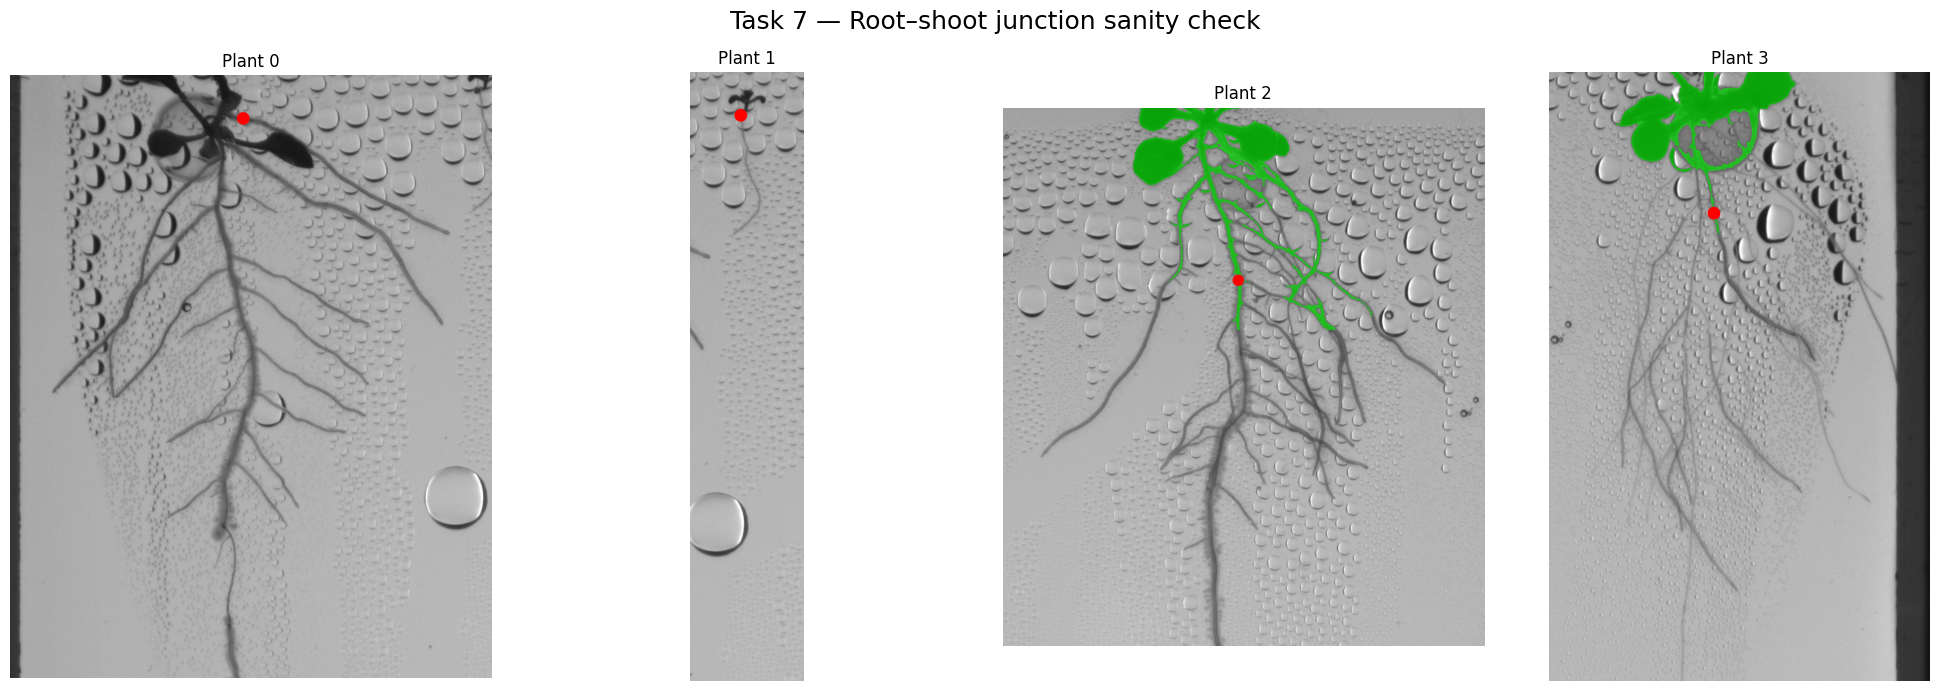

In [86]:
# ============================================================
# SANITY CHECK 7.1
# ROOT–SHOOT JUNCTIONS
# ============================================================

fig, axes = plt.subplots(
    1,
    len(individual_root_masks),
    figsize=(5 * len(individual_root_masks), 7)
)

if len(individual_root_masks) == 1:
    axes = [axes]


for plant_id, ax in enumerate(axes):

    display = image.copy()

    shoot = shoot_masks[plant_id] > 0

    display[shoot] = (
        0.4 * display[shoot]
        + 0.6 * np.array([0, 255, 0])
    ).astype(np.uint8)

    junction = root_shoot_junctions[
        plant_id
    ]

    if junction is not None:

        jy, jx = junction

        cv2.circle(
            display,
            (jx, jy),
            12,
            (255, 0, 0),
            -1
        )

    root_mask = individual_root_masks[
        plant_id
    ]

    ys, xs = np.where(root_mask > 0)

    padding = 80

    xmin = max(0, xs.min() - padding)
    xmax = min(
        display.shape[1],
        xs.max() + padding + 1
    )

    ymin = max(
        0,
        min(
            ys.min(),
            junction[0] if junction else ys.min()
        ) - padding
    )

    ymax = min(
        display.shape[0],
        ys.min() + int(0.35 * display.shape[0])
    )

    ax.imshow(
        display[
            ymin:ymax,
            xmin:xmax
        ]
    )

    ax.set_title(
        f"Plant {plant_id}"
    )

    ax.axis("off")


plt.suptitle(
    "Task 7 — Root–shoot junction sanity check",
    fontsize=18
)

plt.tight_layout()
plt.show()

# Second attempt

In [87]:
# ============================================================
# root architecture extraction — ATTEMPT 2
# Bottom-up primary root extraction
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from skimage.morphology import skeletonize
from scipy.spatial import cKDTree

In [88]:
# ============================================================
# STEP 1 — Skeleton + root thickness
# ============================================================

root_skeletons = []
root_thickness_maps = []

for plant_id, mask in enumerate(individual_root_masks):

    binary = (mask > 0).astype(np.uint8)

    skeleton = skeletonize(binary.astype(bool))

    # Distance to background.
    # Larger value = thicker part of the root.
    thickness = cv2.distanceTransform(
        binary,
        cv2.DIST_L2,
        5
    )

    root_skeletons.append(skeleton)
    root_thickness_maps.append(thickness)

print(f"Prepared {len(root_skeletons)} root systems.")

Prepared 4 root systems.


In [89]:
# ============================================================
# STEP 2 — Detect skeleton endpoints
# ============================================================

def get_skeleton_endpoints(skeleton):

    skel = skeleton.astype(np.uint8)

    kernel = np.ones(
        (3, 3),
        dtype=np.uint8
    )

    neighbour_sum = cv2.filter2D(
        skel,
        -1,
        kernel,
        borderType=cv2.BORDER_CONSTANT
    )

    # Centre pixel itself contributes 1.
    # Endpoint therefore has:
    # 1 centre + exactly 1 neighbour = 2.
    endpoint_mask = (
        (skel == 1) &
        (neighbour_sum == 2)
    )

    return np.column_stack(
        np.where(endpoint_mask)
    )

In [90]:
# ============================================================
# STEP 3 — Find plausible deep root-tip candidates
# ============================================================

primary_tip_candidates = []

for plant_id, skeleton in enumerate(root_skeletons):

    endpoints = get_skeleton_endpoints(skeleton)

    ys, xs = np.where(skeleton)

    root_top = ys.min()
    root_bottom = ys.max()

    root_height = root_bottom - root_top

    # Keep endpoints close to the deepest part of the root system.
    depth_band = max(
        25,
        int(0.15 * root_height)
    )

    deepest_allowed_y = (
        root_bottom - depth_band
    )

    candidates = np.array([
        (y, x)
        for y, x in endpoints
        if y >= deepest_allowed_y
    ])

    primary_tip_candidates.append(candidates)

    print(
        f"Plant {plant_id}: "
        f"{len(endpoints)} total endpoints, "
        f"{len(candidates)} deep candidates"
    )

Plant 0: 40 total endpoints, 1 deep candidates
Plant 1: 2 total endpoints, 1 deep candidates
Plant 2: 50 total endpoints, 1 deep candidates
Plant 3: 117 total endpoints, 6 deep candidates


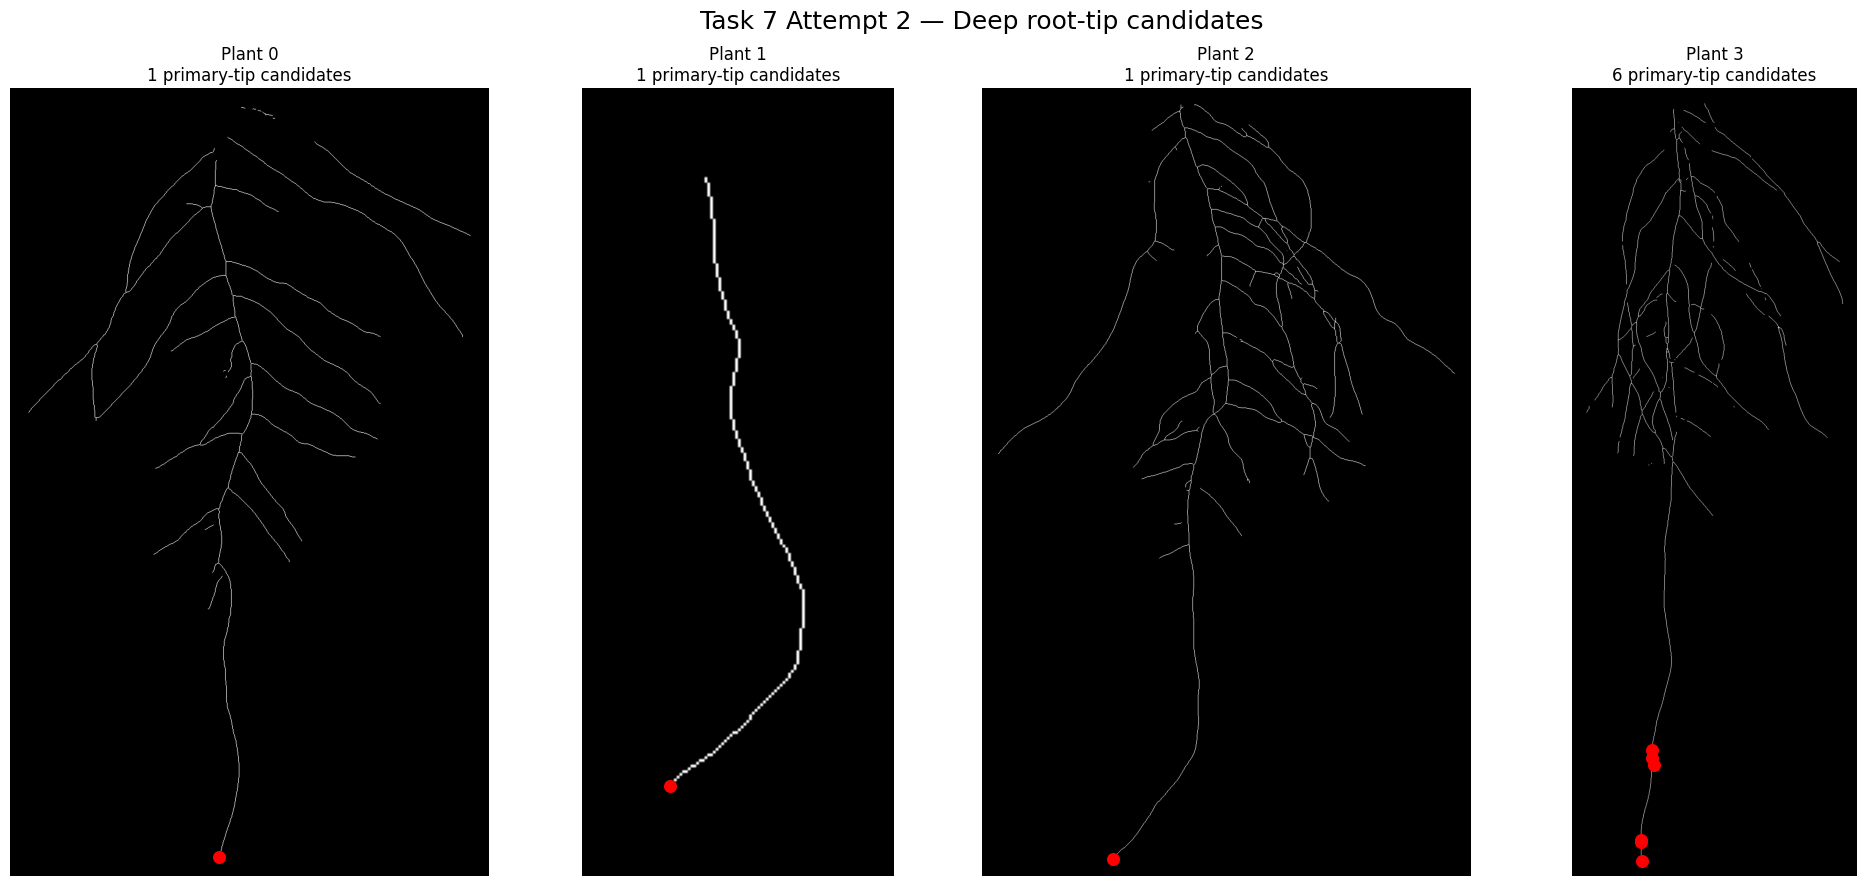

In [91]:
# ============================================================
# SANITY CHECK 7A
# Deep primary-root tip candidates
# ============================================================

fig, axes = plt.subplots(
    1,
    len(root_skeletons),
    figsize=(5 * len(root_skeletons), 9)
)

if len(root_skeletons) == 1:
    axes = [axes]

for plant_id, ax in enumerate(axes):

    skeleton = root_skeletons[plant_id]
    candidates = primary_tip_candidates[plant_id]

    ys, xs = np.where(
        individual_root_masks[plant_id] > 0
    )

    padding = 30

    xmin = max(0, xs.min() - padding)
    xmax = min(
        skeleton.shape[1],
        xs.max() + padding + 1
    )

    ymin = max(0, ys.min() - padding)
    ymax = min(
        skeleton.shape[0],
        ys.max() + padding + 1
    )

    ax.imshow(
        skeleton[
            ymin:ymax,
            xmin:xmax
        ],
        cmap="gray"
    )

    for y, x in candidates:

        ax.scatter(
            x - xmin,
            y - ymin,
            s=70,
            c="red"
        )

    ax.set_title(
        f"Plant {plant_id}\n"
        f"{len(candidates)} primary-tip candidates"
    )

    ax.axis("off")

plt.suptitle(
    "Task 7 Attempt 2 — Deep root-tip candidates",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [92]:
# ============================================================
# root architecture extraction — ATTEMPT 2, STEP 4
# Build weighted bottom-up root graph
# ============================================================

def build_bottom_up_graph(
    skeleton,
    thickness_map,
    max_gap_px,
    plant_center_x
):

    skeleton = skeleton.astype(bool)

    G = nx.DiGraph()

    ys, xs = np.where(skeleton)

    # Normalise root thickness
    thickness_values = thickness_map[skeleton]

    thickness_scale = np.percentile(
        thickness_values,
        95
    )

    thickness_scale = max(
        thickness_scale,
        1e-6
    )

    # --------------------------------------------------------
    # Real skeleton edges
    # --------------------------------------------------------

    neighbour_steps = [
        (-1,  0),
        (-1, -1),
        (-1,  1),
        ( 0, -1),
        ( 0,  1),
        ( 1, -1),
        ( 1,  0),
        ( 1,  1)
    ]

    h, w = skeleton.shape

    for y, x in zip(ys, xs):

        node = (int(y), int(x))

        G.add_node(node)

        for dy, dx in neighbour_steps:

            ny = y + dy
            nx_ = x + dx

            if not (
                0 <= ny < h and
                0 <= nx_ < w and
                skeleton[ny, nx_]
            ):
                continue

            step_length = np.hypot(
                dy,
                dx
            )

            local_thickness = (
                thickness_map[y, x]
                + thickness_map[ny, nx_]
            ) / 2

            thickness_norm = np.clip(
                local_thickness / thickness_scale,
                0,
                1
            )

            # Prefer thicker root regions
            thickness_penalty = (
                1.0
                + 0.8 * (1.0 - thickness_norm)
            )

            # We are travelling BOTTOM -> TOP.
            #
            # upward  = cheap
            # sideways = somewhat expensive
            # downward = strongly discouraged
            if dy < 0:
                direction_penalty = 1.0

            elif dy == 0:
                direction_penalty = 1.35

            else:
                direction_penalty = 3.0

            weight = (
                step_length
                * thickness_penalty
                * direction_penalty
            )

            G.add_edge(
                node,
                (int(ny), int(nx_)),
                weight=float(weight),
                real=True
            )

    # --------------------------------------------------------
    # Virtual edges across segmentation gaps
    # --------------------------------------------------------

    n_components, labels = cv2.connectedComponents(
        skeleton.astype(np.uint8),
        connectivity=8
    )

    endpoints = get_skeleton_endpoints(
        skeleton
    )

    endpoint_info = []

    for y, x in endpoints:

        endpoint_info.append({
            "point": (int(y), int(x)),
            "component": int(labels[y, x])
        })

    for a in endpoint_info:

        y1, x1 = a["point"]

        for b in endpoint_info:

            if a["component"] == b["component"]:
                continue

            y2, x2 = b["point"]

            # Bottom-up:
            # destination must actually be ABOVE source
            vertical_gain = y1 - y2

            if vertical_gain <= 0:
                continue

            distance = np.hypot(
                y2 - y1,
                x2 - x1
            )

            if distance > max_gap_px:
                continue

            # Reject almost purely sideways jumps
            if vertical_gain < 0.15 * distance:
                continue

            horizontal_shift = abs(
                x2 - x1
            )

            # Gap crossing is deliberately expensive.
            gap_weight = (
                6.0 * distance
                + 1.5 * horizontal_shift
            )

            G.add_edge(
                (y1, x1),
                (y2, x2),
                weight=float(gap_weight),
                real=False
            )

    return G

In [93]:
# ============================================================
# STEP 5 — Bottom-up primary-root path
# ============================================================

def find_primary_root_bottom_up(
    skeleton,
    thickness_map,
    deep_candidates,
    plant_center_x,
    max_gap_px
):

    if len(deep_candidates) == 0:
        return None

    # --------------------------------------------------------
    # START = deepest detected root tip
    # --------------------------------------------------------

    deepest_y = deep_candidates[:, 0].max()

    deepest = deep_candidates[
        deep_candidates[:, 0] == deepest_y
    ]

    # If tied, prefer candidate horizontally closest to plant
    start_idx = np.argmin(
        np.abs(
            deepest[:, 1]
            - plant_center_x
        )
    )

    start = tuple(
        deepest[start_idx].astype(int)
    )

    # --------------------------------------------------------
    # Build graph
    # --------------------------------------------------------

    G = build_bottom_up_graph(
        skeleton,
        thickness_map,
        max_gap_px,
        plant_center_x
    )

    ys, xs = np.where(skeleton)

    root_top = ys.min()
    root_bottom = ys.max()
    root_height = root_bottom - root_top

    # --------------------------------------------------------
    # TARGET = upper part of root system
    #
    # We use a REGION, not one guessed crown pixel.
    # --------------------------------------------------------

    top_limit = (
        root_top
        + max(
            20,
            int(0.12 * root_height)
        )
    )

    horizontal_limit = int(
        0.08 * skeleton.shape[1]
    )

    target_nodes = [
        (int(y), int(x))
        for y, x in zip(ys, xs)
        if (
            y <= top_limit
            and abs(x - plant_center_x)
            <= horizontal_limit
        )
    ]

    # Fallback if unusually curved root misses corridor
    if len(target_nodes) == 0:

        target_nodes = [
            (int(y), int(x))
            for y, x in zip(ys, xs)
            if y <= top_limit
        ]

    # --------------------------------------------------------
    # Virtual sink:
    # allows Dijkstra to choose the best upper destination.
    # --------------------------------------------------------

    sink = ("SINK",)

    G.add_node(sink)

    for node in target_nodes:

        y, x = node

        centre_penalty = (
            0.05
            * abs(x - plant_center_x)
        )

        G.add_edge(
            node,
            sink,
            weight=float(centre_penalty),
            real=False
        )

    try:

        path_to_sink = nx.shortest_path(
            G,
            source=start,
            target=sink,
            weight="weight"
        )

        optimisation_cost = nx.shortest_path_length(
            G,
            source=start,
            target=sink,
            weight="weight"
        )

    except nx.NetworkXNoPath:

        return None

    # Remove virtual sink
    path = path_to_sink[:-1]

    # --------------------------------------------------------
    # Calculate actual estimated biological length
    # --------------------------------------------------------

    length_px = 0.0
    gap_edges = []

    for a, b in zip(
        path[:-1],
        path[1:]
    ):

        y1, x1 = a
        y2, x2 = b

        step = np.hypot(
            y2 - y1,
            x2 - x1
        )

        length_px += step

        edge_data = G[a][b]

        if not edge_data["real"]:

            gap_edges.append(
                (a, b, step)
            )

    return {
        "start_tip": start,
        "end_point": path[-1],
        "path": path,
        "length_px": float(length_px),
        "optimisation_cost": float(optimisation_cost),
        "gap_edges": gap_edges,
        "target_nodes": target_nodes
    }

In [94]:
# ============================================================
# STEP 6 — Run bottom-up tracker
# ============================================================

PRIMARY_GAP_RATIO = 0.020

primary_results = []

for plant_id in range(
    len(individual_root_masks)
):

    skeleton = root_skeletons[
        plant_id
    ]

    gap_px = max(
        2,
        int(
            PRIMARY_GAP_RATIO
            * min(skeleton.shape)
        )
    )

    result = find_primary_root_bottom_up(
        skeleton=skeleton,
        thickness_map=root_thickness_maps[plant_id],
        deep_candidates=primary_tip_candidates[plant_id],
        plant_center_x=plant_centers[plant_id],
        max_gap_px=gap_px
    )

    primary_results.append(
        result
    )

    if result is None:

        print(
            f"Plant {plant_id}: FAILED"
        )

    else:

        print(
            f"Plant {plant_id}: "
            f"{result['length_px']:.1f}px, "
            f"{len(result['gap_edges'])} gap jump(s)"
        )

Plant 0: 1209.8px, 0 gap jump(s)
Plant 1: 230.6px, 0 gap jump(s)
Plant 2: 1375.6px, 0 gap jump(s)
Plant 3: 1524.4px, 2 gap jump(s)


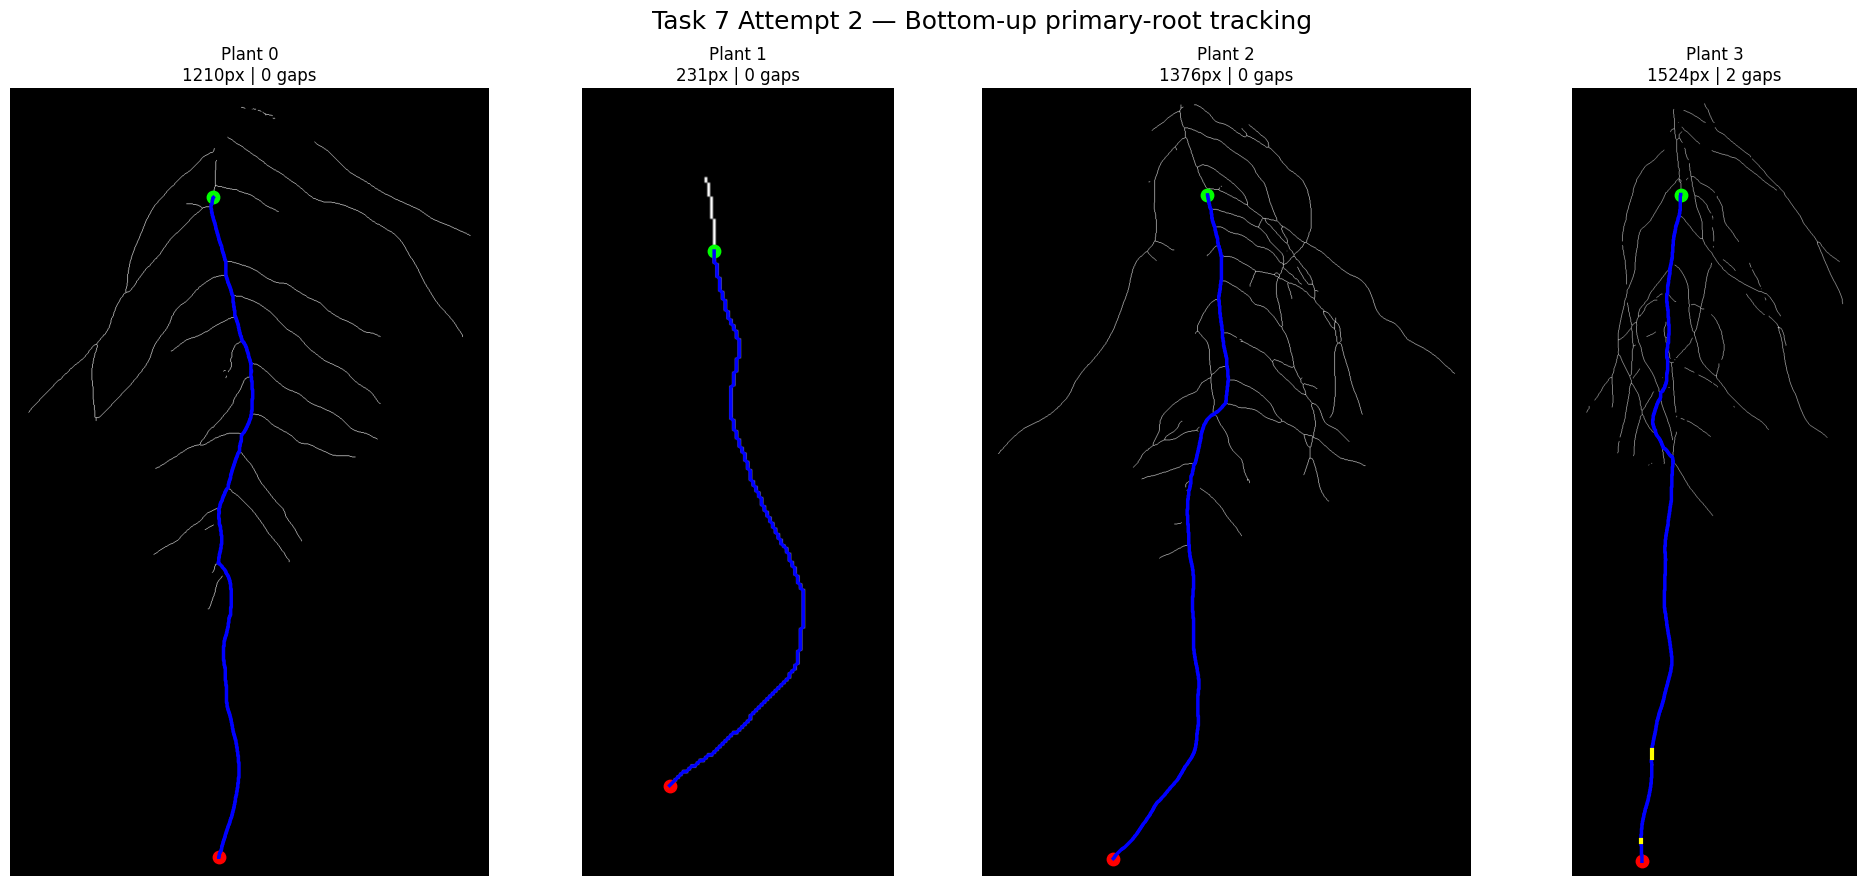

In [95]:
# ============================================================
# SANITY CHECK 7B
# Bottom-up predicted primary root
# ============================================================

fig, axes = plt.subplots(
    1,
    len(primary_results),
    figsize=(5 * len(primary_results), 9)
)

if len(primary_results) == 1:
    axes = [axes]


for plant_id, ax in enumerate(axes):

    skeleton = root_skeletons[
        plant_id
    ]

    result = primary_results[
        plant_id
    ]

    ys, xs = np.where(
        individual_root_masks[plant_id] > 0
    )

    padding = 30

    xmin = max(
        0,
        xs.min() - padding
    )

    xmax = min(
        skeleton.shape[1],
        xs.max() + padding + 1
    )

    ymin = max(
        0,
        ys.min() - padding
    )

    ymax = min(
        skeleton.shape[0],
        ys.max() + padding + 1
    )

    ax.imshow(
        skeleton[
            ymin:ymax,
            xmin:xmax
        ],
        cmap="gray"
    )

    if result is not None:

        path = np.array(
            result["path"]
        )

        ax.plot(
            path[:, 1] - xmin,
            path[:, 0] - ymin,
            linewidth=2.5,
            color="blue"
        )

        sy, sx = result[
            "start_tip"
        ]

        ey, ex = result[
            "end_point"
        ]

        ax.scatter(
            sx - xmin,
            sy - ymin,
            s=80,
            color="red"
        )

        ax.scatter(
            ex - xmin,
            ey - ymin,
            s=80,
            color="lime"
        )

        for a, b, distance in result[
            "gap_edges"
        ]:

            y1, x1 = a
            y2, x2 = b

            ax.plot(
                [x1 - xmin, x2 - xmin],
                [y1 - ymin, y2 - ymin],
                linewidth=3,
                color="yellow"
            )

        ax.set_title(
            f"Plant {plant_id}\n"
            f"{result['length_px']:.0f}px | "
            f"{len(result['gap_edges'])} gaps"
        )

    else:

        ax.set_title(
            f"Plant {plant_id}\nFAILED"
        )

    ax.axis("off")


plt.suptitle(
    "Task 7 Attempt 2 — Bottom-up primary-root tracking",
    fontsize=18
)

plt.tight_layout()
plt.show()

# root architecture extraction — RSA Extraction with RootNav 2.0

individual root assignment provides individual root masks using the custom U-Net root segmentation segmentation model.

For root architecture extraction, the pretrained RootNav 2.0 Arabidopsis model is used to obtain
semantic plant landmarks, particularly seed/root-origin locations and
primary-root tip locations.

These semantic landmarks are combined with the custom U-Net root segmentation/6 root masks
to identify and measure the primary root architecture.